# **Project Title:** AI-Powered IoT Network Anomaly Detection and Investigation Platform

## Phase 4: Explain Stacking Predictions with SHAP

| Item | Details |
|---|---|
| Model | Stacking DT + RF + HGB → XGBoost `XGB_d4_n200` |
| Source run | `xgb_meta_20261021_092334_9024562d` |
| Mục tiêu | Giải thích vì sao model dự đoán một mẫu thành một lớp cụ thể |
| XAI | Chỉ SHAP, giải thích trên các đặc trưng mạng gốc |
| Output | Nhãn/xác suất, top 5 đặc trưng, SHAP value có dấu và waterfall |
| Nơi chạy | Kaggle; không train lại model |

**Add Input** hai output đầy đủ:
1. Output của `ciciot2023-do-an-stacking-xgboost-meta.ipynb`.
2. Output processing `20261021_052521_96f61f19`.

Giữ `XGB_DIR=None`, `DATA_DIR=None` để tự tìm, sau đó **Restart Session → Run All**.
Output SHAP ghi vào `/kaggle/working/xai_shap_runs/<run_id>/`.


## Phạm vi giải thích

- Giữ nguyên bundle đã chốt và pipeline suy luận của notebook nguồn. Không fit/tune/resampling, không dùng LIME hoặc gọi LLM.
- XGBoost meta nhận 24 xác suất từ ba base models. Ở đây SHAP bao quanh **toàn pipeline** để đóng góp thuộc về đặc trưng mạng gốc.
- Dùng `PermutationExplainer`, background lấy ngẫu nhiên từ **train**, mẫu cần giải thích lấy từ **validation**. Không nạp test.
- Đầu ra được giải thích là **xác suất của từng lớp**, không phải log-odds. Với lớp đang xét: `base_probability + sum(SHAP) ≈ predicted_probability`.
- SHAP dương/âm thể hiện đóng góp vào xác suất lớp đang xét so với background; không có nghĩa cứ tăng giá trị đặc trưng là xác suất sẽ tăng/giảm.
- Hình 1, trang 3 của bài báo *An Adaptive End-to-End IoT Security Framework Using Explainable AI and LLMs* nối model → XAI → các đặc trưng ảnh hưởng → LLM/dashboard. Đồ án hiện chỉ làm khối SHAP; JSON từng mẫu chuẩn bị dữ liệu cho bước tích hợp sau.


# Import Library


In [1]:
import gc
import hashlib
import importlib.util
import json
import os
import platform
import time
import uuid
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import HTML, display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from threadpoolctl import threadpool_info

try:
    import shap
except ImportError as error:
    raise RuntimeError(
        "Cần cài SHAP tương thích với môi trường nguồn rồi restart. "
        "Giữ nguyên NumPy/pandas/scikit-learn/joblib/XGBoost của run nguồn."
    ) from error

# Thiết lập phong cách đồ thị chuẩn báo cáo đồ án tốt nghiệp
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.edgecolor"] = "#cbd5e1"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.color"] = "#f1f5f9"
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.alpha"] = 0.7

## 1. Configuration


In [2]:
# XGB_DIR: thư mục run có protocol.json, predict_csv.py và frozen_models/.
# DATA_DIR: thư mục processing có preprocessing_config.json, X/y và checksums.json.
XGB_DIR = "/kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-stacking-xgboost-meta/stacking_meta_runs/xgb_meta_20261021_092334_9024562d"
DATA_DIR = "/kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-processing/processed_data/20261021_052521_96f61f19"
SOURCE_RUN_ID = "xgb_meta_20261021_092334_9024562d"
MODEL_ID = "XGB_d4_n200"

RANDOM_STATE = 42
N_JOBS = 2
PREDICT_BATCH_SIZE = 4096
BACKGROUND_SIZE = 32
PERMUTATION_BUDGET = 5
TOP_FEATURES = 5
ADDITIVITY_TOLERANCE = 1e-5

# Mặc định: tối đa 1 mẫu đúng và 1 mẫu sai cho mỗi lớp thật, tối đa 16 mẫu.
# Chỉ số này là dòng của validation SAU processing, bắt đầu từ 0.
# Ví dụ muốn giải thích riêng hai dòng: MANUAL_VAL_INDICES = [100, 200].
MANUAL_VAL_INDICES = []
CORRECT_PER_CLASS = 1
WRONG_PER_CLASS = 1
MAX_CASES = 16

CLASS_NAMES = [
    "Normal", "BruteForce", "DDoS", "DoS",
    "Mirai", "Recon", "Spoofing", "Web-Based",
]
CLASS_IDS = np.arange(8)
BASE_NAMES = ["DT", "RF", "HGB"]
PROTOCOL = "stacking_shap_local_v1"

if not Path("/kaggle/input").is_dir() or not Path("/kaggle/working").is_dir():
    raise RuntimeError("Chỉ xử lý dữ liệu và chạy SHAP trên Kaggle.")
if BACKGROUND_SIZE < 2 or PERMUTATION_BUDGET < 1 or MAX_CASES < 1:
    raise ValueError("Background/budget/số mẫu không hợp lệ.")
if CORRECT_PER_CLASS < 0 or WRONG_PER_CLASS < 0 or TOP_FEATURES < 1 or ADDITIVITY_TOLERANCE <= 0:
    raise ValueError("Cấu hình giải thích không hợp lệ.")

RUN_ID = "shap_" + time.strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]
OUTPUT_DIR = Path("/kaggle/working/xai_shap_runs") / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
SESSION_START = time.perf_counter()
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

print("═" * 78)
print(" 🔍 CẤU HÌNH GIẢI THÍCH CỤC BỘ BẰNG SHAP (LOCAL EXPLANATION CONFIGURATION)")
print("═" * 78)
config_summary = pd.DataFrame([
    {"Tham số": "Source Stacking Run", "Giá trị": SOURCE_RUN_ID, "Ý nghĩa thực nghiệm": "Run mô hình nguồn đã đóng băng"},
    {"Tham số": "Candidate Model", "Giá trị": MODEL_ID, "Ý nghĩa thực nghiệm": "Stacking DT+RF+HGB -> XGBoost Meta"},
    {"Tham số": "SHAP Output Run", "Giá trị": RUN_ID, "Ý nghĩa thực nghiệm": "Thư mục lưu trữ artifact giải thích"},
    {"Tham số": "Background Size", "Giá trị": f"{BACKGROUND_SIZE} mẫu", "Ý nghĩa thực nghiệm": "Mẫu nền đối chứng lấy từ tập Train"},
    {"Tham số": "Permutation Budget", "Giá trị": f"{PERMUTATION_BUDGET} vòng", "Ý nghĩa thực nghiệm": "Ngân sách hoán vị đặc trưng PermutationExplainer"},
    {"Tham số": "Max Explanation Cases", "Giá trị": f"{MAX_CASES} mẫu", "Ý nghĩa thực nghiệm": "Tối đa 1 đúng + 1 sai cho mỗi lớp từ Validation"},
    {"Tham số": "Top Features Trích xuất", "Giá trị": f"{TOP_FEATURES} đặc trưng", "Ý nghĩa thực nghiệm": "Số đặc trưng có đóng góp lớn nhất lưu chi tiết"},
    {"Tham số": "Kiểm soát rò rỉ", "Giá trị": "Zero Leakage", "Ý nghĩa thực nghiệm": "KHÔNG nạp tập Test; không refit preprocessor hay model"},
])
display(config_summary)
print(f"📁 Thư mục xuất kết quả: {OUTPUT_DIR}\n")

══════════════════════════════════════════════════════════════════════════════
 🔍 CẤU HÌNH GIẢI THÍCH CỤC BỘ BẰNG SHAP (LOCAL EXPLANATION CONFIGURATION)
══════════════════════════════════════════════════════════════════════════════


,Tham số,Giá trị,Ý nghĩa thực nghiệm
0,Source Stacking Run,xgb_meta_20261021_092334_9024562d,Run mô hình nguồn đã đóng băng
1,Candidate Model,XGB_d4_n200,Stacking DT+RF+HGB -> XGBoost Meta
2,SHAP Output Run,shap_20261022_021654_2555e479,Thư mục lưu trữ artifact giải thích
3,Background Size,32 mẫu,Mẫu nền đối chứng lấy từ tập Train
4,Permutation Budget,5 vòng,Ngân sách hoán vị đặc trưng PermutationExplainer
5,Max Explanation Cases,16 mẫu,Tối đa 1 đúng + 1 sai cho mỗi lớp từ Validation
6,Top Features Trích xuất,5 đặc trưng,Số đặc trưng có đóng góp lớn nhất lưu chi tiết
7,Kiểm soát rò rỉ,Zero Leakage,KHÔNG nạp tập Test; không refit preprocessor h...


📁 Thư mục xuất kết quả: /kaggle/working/xai_shap_runs/shap_20261022_021654_2555e479



### Helper Functions — JSON, Checksums and Input Paths


In [3]:
def write_json(path, content):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(content, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        block = file.read(8 * 1024 * 1024)
        while block:
            digest.update(block)
            block = file.read(8 * 1024 * 1024)
    return digest.hexdigest()


def find_run(configured_dir, marker, run_id, description):
    if configured_dir is not None:
        directory = Path(configured_dir)
        if not (directory / marker).is_file():
            raise FileNotFoundError(
                f"{description}: thiếu {marker} tại {directory}. "
                "Kiểm tra loại output và trỏ đúng thư mục run."
            )
        return directory
    matches = []
    for path in Path("/kaggle/input").rglob(marker):
        content = json.loads(path.read_text())
        if content.get("run_id") == run_id:
            matches.append(path.parent)
    if len(matches) != 1:
        raise FileNotFoundError(
            f"{description}: cần đúng một run {run_id}, tìm thấy {matches}. "
            "Add Input output đầy đủ hoặc điền đường dẫn thư mục run rõ ràng."
        )
    return matches[0]


def print_step_header(step_num, title, detail=None):
    """In tiêu đề bước thực hiện theo phong cách báo cáo đồ án rõ ràng, trực quan."""
    print("\n" + "═" * 78)
    print(f" 📌 BƯỚC {step_num}: {title.upper()}")
    if detail:
        print(f"    ↳ {detail}")
    print("═" * 78)

## 2. Verify the Frozen XGBoost Model and Library Versions


In [4]:
print_step_header(2, "XÁC THỰC MÔ HÌNH VÀ PHIÊN BẢN THƯ VIỆN NGUỒN", "Kiểm tra bundle Stacking đã freeze, checksums và môi trường thực thi")
XGB_DIR = find_run(XGB_DIR, "protocol.json", SOURCE_RUN_ID, "Output XGBoost nguồn")

# Run XGBoost gốc lưu các báo cáo ở thư mục run, không nằm trong frozen_models/.
required_source_files = [
    "protocol.json", "run_status.json", "predict_csv.py", "source_artifacts.json",
    "frozen_candidates.json", "output_checksums.json", "reload_checks.json",
    "validation_comparison.csv",
]
missing_files = []
for file_name in required_source_files:
    if not (XGB_DIR / file_name).is_file():
        missing_files.append(file_name)
if missing_files:
    raise FileNotFoundError(
        f"Source run thiếu {missing_files} tại {XGB_DIR}. "
        "Gắn output XGBoost meta đầy đủ và trỏ XGB_DIR vào thư mục run. "
        "frozen_candidates.json, output_checksums.json và reload_checks.json nằm cạnh protocol.json."
    )

source_protocol = json.loads((XGB_DIR / "protocol.json").read_text())
source_status = json.loads((XGB_DIR / "run_status.json").read_text())
source_freeze = json.loads((XGB_DIR / "frozen_candidates.json").read_text())
source_checksums = json.loads((XGB_DIR / "output_checksums.json").read_text())
source_reload = json.loads((XGB_DIR / "reload_checks.json").read_text())
source_artifacts = json.loads((XGB_DIR / "source_artifacts.json").read_text())

SOURCE_PROTOCOL_SHA256 = sha256_file(XGB_DIR / "protocol.json")
if source_status["status"] != "complete":
    raise ValueError("Run nguồn chưa hoàn tất.")
for record in [source_protocol, source_status, source_freeze]:
    if record["run_id"] != SOURCE_RUN_ID:
        raise ValueError("Protocol/status/freeze không cùng SOURCE_RUN_ID.")
if source_protocol["protocol"] != "stacking_xgb_meta_v1":
    raise ValueError("Cần output XGBoost meta gốc với protocol stacking_xgb_meta_v1.")
if source_protocol["base_names"] != BASE_NAMES or source_protocol["class_names"] != CLASS_NAMES:
    raise ValueError("Source protocol không khớp thứ tự base models hoặc lớp.")
if source_freeze["primary_candidate_id"] != MODEL_ID:
    raise ValueError(
        f"Model chính đã freeze ({source_freeze['primary_candidate_id']}) khác MODEL_ID={MODEL_ID}."
    )

# Xác thực cả các tệp điều khiển và helper trước khi thực thi helper/nạp bundle.
for file_name in [
    "protocol.json", "frozen_candidates.json", "source_artifacts.json",
    "reload_checks.json", "predict_csv.py", "validation_comparison.csv",
]:
    if sha256_file(XGB_DIR / file_name) != source_checksums.get(file_name):
        raise ValueError(f"Source checksum không khớp: {file_name}")
for file_name, key in [
    ("protocol.json", "protocol_sha256"),
    ("source_artifacts.json", "source_artifacts_sha256"),
    ("validation_comparison.csv", "validation_table_sha256"),
]:
    if sha256_file(XGB_DIR / file_name) != source_freeze[key]:
        raise ValueError(f"Source freeze checksum không khớp: {file_name}")

model_records = []
for item in source_freeze["candidates"]:
    if item["candidate_id"] == MODEL_ID:
        model_records.append(item)
if len(model_records) != 1 or model_records[0]["kind"] != "xgboost_meta":
    raise ValueError(f"Cần đúng một XGBoost candidate đã freeze: {MODEL_ID}.")
model_record = model_records[0]
bundle_path = XGB_DIR / model_record["bundle_file"]
if not bundle_path.is_file():
    raise FileNotFoundError(f"Thiếu bundle: {bundle_path}")
if sha256_file(bundle_path) != model_record["sha256"]:
    raise ValueError("Frozen bundle checksum không khớp.")
if source_checksums.get(model_record["bundle_file"]) != model_record["sha256"]:
    raise ValueError("Source manifest/freeze không cùng bundle.")
if not any(row["candidate_id"] == MODEL_ID and row["passed"] for row in source_reload):
    raise ValueError("Model nguồn chưa có reload/CSV checks thành công.")

versions = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "sklearn": sklearn.__version__, "joblib": joblib.__version__, "xgboost": xgboost.__version__,
    "shap": shap.__version__, "matplotlib": matplotlib.__version__,
}
# Kiểm tra trước khi nạp sklearn objects từ joblib; không tự nâng thư viện nguồn.
for package in ["numpy", "pandas", "sklearn", "joblib", "xgboost"]:
    if source_protocol["versions"][package] != versions[package]:
        raise RuntimeError(
            f"Dùng {package}=={source_protocol['versions'][package]} như run nguồn; "
            f"hiện tại {versions[package]}. Cài đúng phiên bản rồi restart."
        )

# Tái sử dụng nguyên helper đã được checksum thay vì viết một pipeline dự đoán khác.
helper_path = OUTPUT_DIR / "predict_csv.py"
helper_path.write_bytes((XGB_DIR / "predict_csv.py").read_bytes())
spec = importlib.util.spec_from_file_location("source_stacking_prediction", helper_path)
prediction_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prediction_module)
bundle = prediction_module.load_bundle(bundle_path)
if bundle["candidate_id"] != MODEL_ID or bundle["kind"] != "stacking":
    raise ValueError("Bundle không đúng model đã chọn.")
if bundle["base_names"] != BASE_NAMES or bundle["class_names"] != CLASS_NAMES:
    raise ValueError("Bundle class/base order không khớp.")
if bundle["meta_model"].__class__.__name__ != "XGBClassifier":
    raise ValueError("Meta-model phải là XGBoost.")
bundle["threads"] = N_JOBS

verify_df = pd.DataFrame([
    {"Hạng mục": "Mô hình mục tiêu", "Giá trị": MODEL_ID, "Trạng thái": "✅ Hợp lệ"},
    {"Hạng mục": "Cấu trúc Stacking", "Giá trị": f"Base: {BASE_NAMES} -> Meta: XGBClassifier", "Trạng thái": "✅ Khớp"},
    {"Hạng mục": "Bundle Checksum (SHA256)", "Giá trị": f"{model_record['sha256'][:16]}...{model_record['sha256'][-8:]}", "Trạng thái": "✅ Đã xác thực"},
    {"Hạng mục": "Thư viện nguồn", "Giá trị": f"Python {versions['python']}, sklearn {versions['sklearn']}, xgb {versions['xgboost']}, shap {versions['shap']}", "Trạng thái": "✅ Khớp 5 thư viện nguồn; SHAP đã import"},
])
display(verify_df)
print(f"XGBoost input: {XGB_DIR}")
print(f"Model bundle : {bundle_path}")
print("[OK] Mô hình nguồn, bundle đã đóng băng và các phiên bản thư viện đã được xác thực thành công.")


══════════════════════════════════════════════════════════════════════════════
 📌 BƯỚC 2: XÁC THỰC MÔ HÌNH VÀ PHIÊN BẢN THƯ VIỆN NGUỒN
    ↳ Kiểm tra bundle Stacking đã freeze, checksums và môi trường thực thi
══════════════════════════════════════════════════════════════════════════════


,Hạng mục,Giá trị,Trạng thái
0,Mô hình mục tiêu,XGB_d4_n200,✅ Hợp lệ
1,Cấu trúc Stacking,"Base: ['DT', 'RF', 'HGB'] -> Meta: XGBClassifier",✅ Khớp
2,Bundle Checksum (SHA256),72d62f8760e48287...7f389033,✅ Đã xác thực
3,Thư viện nguồn,"Python 3.13.15, sklearn 1.6.1, xgb 3.4.1, shap...",✅ Khớp 5 thư viện nguồn; SHAP đã import


XGBoost input: /kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-stacking-xgboost-meta/stacking_meta_runs/xgb_meta_20261021_092334_9024562d
Model bundle : /kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-stacking-xgboost-meta/stacking_meta_runs/xgb_meta_20261021_092334_9024562d/frozen_models/XGB_d4_n200.joblib
[OK] Mô hình nguồn, bundle đã đóng băng và các phiên bản thư viện đã được xác thực thành công.


## 3. Load the Exact Processing Run — Train Background and Validation Only


In [5]:
print_step_header(3, "NẠP VÀ KIỂM TRA DỮ LIỆU ĐÃ TIỀN XỬ LÝ", "Nạp tập Train (lấy background) và Validation (chọn mẫu giải thích)")
DATA_RUN_ID = source_protocol["data_run_id"]
DATA_DIR = find_run(DATA_DIR, "preprocessing_config.json", DATA_RUN_ID, "Output processing")
data_config = json.loads((DATA_DIR / "preprocessing_config.json").read_text())
data_status = json.loads((DATA_DIR / "run_status.json").read_text())
schema = json.loads((DATA_DIR / "feature_schema.json").read_text())
data_checksums = json.loads((DATA_DIR / "checksums.json").read_text())
manifest_records = [row for row in source_artifacts if row["category"] == "processing checksum manifest"]
if len(manifest_records) != 1 or sha256_file(DATA_DIR / "checksums.json") != manifest_records[0]["sha256"]:
    raise ValueError("Processing manifest khác dữ liệu của model nguồn.")
if data_status["status"] != "complete" or data_status["run_id"] != DATA_RUN_ID or data_config["run_id"] != DATA_RUN_ID:
    raise ValueError("Processing chưa complete hoặc sai run ID.")
if data_config["protocol"] != "stacking_fixed_split_v1" or data_config["preprocessing_fitted"] is not False:
    raise ValueError("Cần dữ liệu chưa fit, giữ split Kaggle nguồn.")
if data_config["split_policy"]["rows_redistributed"] is not False:
    raise ValueError("Không dùng dữ liệu đã chia lại split.")
feature_names = schema["input_features"]
if feature_names != bundle["feature_names"] or feature_names != data_config["features"]:
    raise ValueError("Feature order không khớp bundle/processing.")
if schema["class_names"] != CLASS_NAMES or data_config["class_names"] != CLASS_NAMES:
    raise ValueError("Processing class order không khớp.")
if bundle["data_run_id"] != DATA_RUN_ID or source_freeze["data_run_id"] != DATA_RUN_ID:
    raise ValueError("Bundle/source freeze không cùng data run.")
if TOP_FEATURES > len(feature_names):
    raise ValueError("TOP_FEATURES lớn hơn số đặc trưng.")

verified_data = {}
for file_name in [
    "preprocessing_config.json", "feature_schema.json", "label_mapping.json",
    "X_train_unprocessed.npy", "X_val_unprocessed.npy", "y_train.npy", "y_val.npy",
    "sample_metadata_val.pkl", "group_id_train.npy", "group_id_val.npy",
]:
    actual = sha256_file(DATA_DIR / file_name)
    if actual != data_checksums.get(file_name):
        raise ValueError(f"Processing checksum không khớp: {file_name}")
    verified_data[file_name] = actual

# mmap chỉ đọc phần background cần dùng; không copy cả X_train vào RAM.
X_train = np.load(DATA_DIR / "X_train_unprocessed.npy", mmap_mode="r", allow_pickle=False)
X_val = np.load(DATA_DIR / "X_val_unprocessed.npy", mmap_mode="r", allow_pickle=False)
y_train = np.load(DATA_DIR / "y_train.npy", allow_pickle=False)
y_val = np.load(DATA_DIR / "y_val.npy", allow_pickle=False)
for values, targets in [(X_train, y_train), (X_val, y_val)]:
    if values.dtype != np.float32 or values.shape != (len(targets), len(feature_names)):
        raise ValueError("Input shape/dtype không khớp.")
    if targets.ndim != 1 or not np.issubdtype(targets.dtype, np.integer):
        raise ValueError("Nhãn phải là vector số nguyên.")
    if not np.array_equal(np.unique(targets), CLASS_IDS):
        raise ValueError("Cần đủ 8 lớp.")

data_table = pd.DataFrame([
    {"Tập dữ liệu": "Train (Background Pool)", "Kích thước": f"{X_train.shape[0]:,} mẫu × {X_train.shape[1]} đặc trưng", "Bộ nhớ": f"{X_train.nbytes / 1024**2:,.1f} MB (mmap)", "Vai trò": "Lấy mẫu nền cho SHAP PermutationExplainer"},
    {"Tập dữ liệu": "Validation (Candidate Pool)", "Kích thước": f"{X_val.shape[0]:,} mẫu × {X_val.shape[1]} đặc trưng", "Bộ nhớ": f"{X_val.nbytes / 1024**2:,.1f} MB (mmap)", "Vai trò": "Trích xuất các ca Đúng/Sai để giải thích"},
    {"Tập dữ liệu": "Test (Khóa độc lập)", "Kích thước": "Chưa nạp (0 mẫu)", "Bộ nhớ": "0 MB", "Vai trò": "Tuân thủ nghiêm ngặt Zero Data Contamination"}
])
display(data_table)
print(f"Processing input : {DATA_DIR}")
print(f"Original features: {len(feature_names)} features | Classes: {len(CLASS_NAMES)}")
print("[OK] Toàn bộ mảng dữ liệu và mã băm SHA256 đã khớp chuẩn xác với run nguồn.")


══════════════════════════════════════════════════════════════════════════════
 📌 BƯỚC 3: NẠP VÀ KIỂM TRA DỮ LIỆU ĐÃ TIỀN XỬ LÝ
    ↳ Nạp tập Train (lấy background) và Validation (chọn mẫu giải thích)
══════════════════════════════════════════════════════════════════════════════


,Tập dữ liệu,Kích thước,Bộ nhớ,Vai trò
0,Train (Background Pool),"4,114,778 mẫu × 46 đặc trưng",722.0 MB (mmap),Lấy mẫu nền cho SHAP PermutationExplainer
1,Validation (Candidate Pool),"755,233 mẫu × 46 đặc trưng",132.5 MB (mmap),Trích xuất các ca Đúng/Sai để giải thích
2,Test (Khóa độc lập),Chưa nạp (0 mẫu),0 MB,Tuân thủ nghiêm ngặt Zero Data Contamination


Processing input : /kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-processing/processed_data/20261021_052521_96f61f19
Original features: 46 features | Classes: 8
[OK] Toàn bộ mảng dữ liệu và mã băm SHA256 đã khớp chuẩn xác với run nguồn.


## 4. Reproduce Validation Predictions Before Explaining Them



══════════════════════════════════════════════════════════════════════════════
 📌 BƯỚC 4: TÁI LẬP KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION
    ↳ Kiểm tra Macro-F1 và xác suất dự đoán khớp 100% với run nguồn
══════════════════════════════════════════════════════════════════════════════
📊 Đánh giá tổng quát: Macro-F1 = 0.896137 | Độ chính xác Accuracy = 99.46%
⏱️ Thời gian suy luận toàn bộ 755,233 dòng validation: 42.10 s (55.74 µs/mẫu)


,precision,recall,f1-score,support
Class,,,,
Normal,0.9217,0.9700,0.9452,"26,176"
BruteForce,0.9762,0.5921,0.7371,277
DDoS,0.9999,0.9999,0.9999,"487,143"
DoS,0.9998,0.9997,0.9997,"165,912"
Mirai,0.9999,0.9999,0.9999,"54,833"
Recon,0.9030,0.8438,0.8724,"8,547"
Spoofing,0.9060,0.8702,0.8877,"11,717"
Web-Based,0.9372,0.5939,0.7271,628


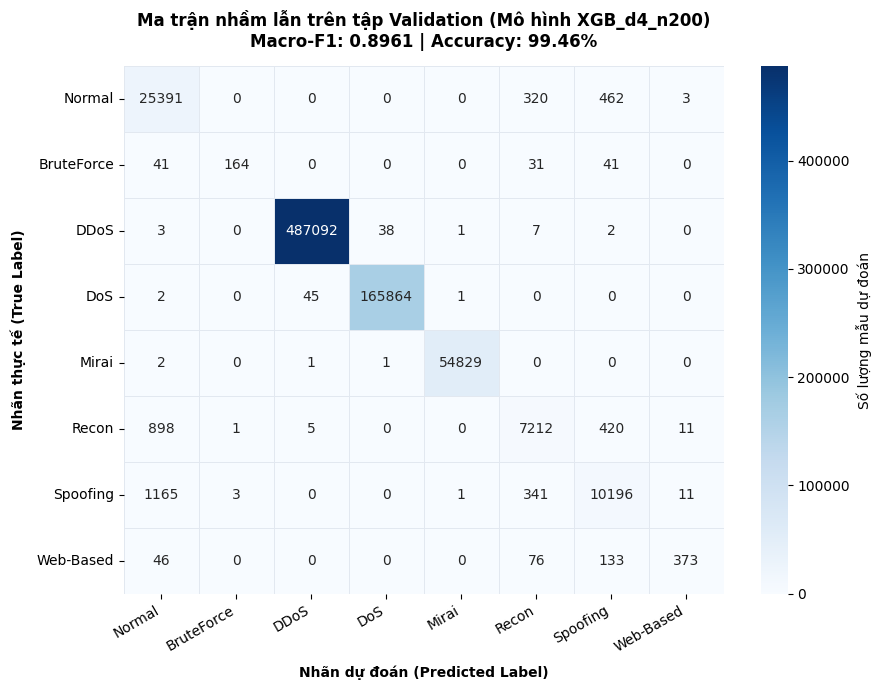

[OK] Xác suất dự đoán và Macro-F1 trên tập Validation tái lập hoàn hảo mô hình Stacking nguồn.


In [6]:
print_step_header(4, "TÁI LẬP KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION", "Kiểm tra Macro-F1 và xác suất dự đoán khớp 100% với run nguồn")
started = time.perf_counter()
val_probabilities = prediction_module.predict_bundle(bundle, X_val, PREDICT_BATCH_SIZE)
validation_predict_seconds = time.perf_counter() - started
val_predictions = val_probabilities.argmax(axis=1)
macro_f1 = float(f1_score(y_val, val_predictions, labels=CLASS_IDS, average="macro", zero_division=0))
if not np.isclose(macro_f1, model_record["validation_macro_f1"], rtol=0, atol=1e-12):
    raise ValueError("Validation macro-F1 không tái lập model nguồn; dừng trước SHAP.")
cached_path = XGB_DIR / f"validation_{MODEL_ID}_probabilities.npy"
cached_probabilities = np.load(cached_path, mmap_mode="r", allow_pickle=False)
if cached_probabilities.shape != val_probabilities.shape or cached_probabilities.dtype != np.float32:
    raise ValueError("Source validation cache schema không khớp.")
np.testing.assert_allclose(val_probabilities, cached_probabilities, rtol=1e-6, atol=1e-7)
np.testing.assert_array_equal(val_predictions, cached_probabilities.argmax(axis=1))
del cached_probabilities

report = classification_report(y_val, val_predictions, labels=CLASS_IDS, target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame([report[name] for name in CLASS_NAMES], index=CLASS_NAMES)
per_class.index.name = "Class"
matrix = confusion_matrix(y_val, val_predictions, labels=CLASS_IDS)
per_class.to_csv(OUTPUT_DIR / "validation_per_class_metrics.csv")
pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_DIR / "validation_confusion_matrix.csv")
write_json(OUTPUT_DIR / "validation_metrics.json", {
    "macro_f1": macro_f1, "accuracy": float(np.mean(val_predictions == y_val)),
    "weighted_f1": float(report["weighted avg"]["f1-score"]),
    "rows": len(y_val), "predict_seconds": validation_predict_seconds,
    "predict_ms_per_row": validation_predict_seconds / len(y_val) * 1000,
    "scope": "raw input -> preprocessing -> DT/RF/HGB -> XGBoost",
    "previously_viewed_validation": True,
})

# Hiển thị bảng chỉ số định dạng chuyên nghiệp
print(f"📊 Đánh giá tổng quát: Macro-F1 = {macro_f1:.6f} | Độ chính xác Accuracy = {np.mean(val_predictions == y_val):.2%}")
print(f"⏱️ Thời gian suy luận toàn bộ {len(X_val):,} dòng validation: {validation_predict_seconds:,.2f} s ({validation_predict_seconds / len(X_val) * 1e6:,.2f} µs/mẫu)")

styled_per_class = per_class.style.format({
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "f1-score": "{:.4f}",
    "support": "{:,.0f}"
}).background_gradient(subset=["f1-score"], cmap="Greens", vmin=0.5, vmax=1.0)
display(styled_per_class)

# Trực quan hóa Ma trận nhầm lẫn chuẩn đồ án tốt nghiệp
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={"label": "Số lượng mẫu dự đoán"}, ax=ax,
    linewidths=0.5, linecolor="#e2e8f0"
)
ax.set_title(
    f"Ma trận nhầm lẫn trên tập Validation (Mô hình {MODEL_ID})\nMacro-F1: {macro_f1:.4f} | Accuracy: {np.mean(val_predictions == y_val):.2%}",
    fontsize=12, fontweight="bold", pad=14
)
ax.set_xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold", labelpad=8)
ax.set_ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold", labelpad=8)
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("[OK] Xác suất dự đoán và Macro-F1 trên tập Validation tái lập hoàn hảo mô hình Stacking nguồn.")

## 5. Select Train Background and Validation Cases


In [7]:
print_step_header(5, "CHỌN MẪU NỀN VÀ CÁC CA ĐẠI DIỆN ĐỂ GIẢI THÍCH", "Lấy 32 mẫu background từ Train và các ca Đúng/Sai từ Validation")
if BACKGROUND_SIZE > len(y_train):
    raise ValueError("BACKGROUND_SIZE lớn hơn tập train.")
rng = np.random.default_rng(RANDOM_STATE)
background_indices = np.sort(rng.choice(len(y_train), size=BACKGROUND_SIZE, replace=False))
background_values = np.array(X_train[background_indices], dtype=np.float32, copy=True)
background_targets = y_train[background_indices]
if np.isinf(background_values).any():
    raise ValueError("Background có Inf.")

if MANUAL_VAL_INDICES:
    selected_indices = np.asarray(MANUAL_VAL_INDICES)
    if selected_indices.ndim != 1 or selected_indices.dtype.kind not in ["i", "u"]:
        raise ValueError("MANUAL_VAL_INDICES phải là danh sách số nguyên.")
    if len(np.unique(selected_indices)) != len(selected_indices):
        raise ValueError("Chỉ số mẫu bị lặp.")
    if np.any(selected_indices < 0) or np.any(selected_indices >= len(y_val)):
        raise ValueError("Chỉ số mẫu ngoài validation sau processing.")
else:
    selected_indices = []
    for class_id in CLASS_IDS:
        correct_rows = np.flatnonzero((y_val == class_id) & (val_predictions == class_id))
        wrong_rows = np.flatnonzero((y_val == class_id) & (val_predictions != class_id))
        for available, requested in [(correct_rows, CORRECT_PER_CLASS), (wrong_rows, WRONG_PER_CLASS)]:
            count = min(requested, len(available))
            if count:
                selected_indices.extend(rng.choice(available, size=count, replace=False).tolist())
    selected_indices = np.asarray(selected_indices, dtype=np.int64)

if len(selected_indices) == 0:
    raise ValueError("Không có mẫu nào được chọn.")
if len(selected_indices) > MAX_CASES:
    selected_indices = selected_indices[:MAX_CASES]

metadata_path = DATA_DIR / "sample_metadata_val.pkl"
val_metadata = joblib.load(metadata_path)
if len(val_metadata) != len(y_val):
    raise ValueError("Metadata validation không khớp độ dài nhãn.")

case_rows = []
for order, index in enumerate(selected_indices, start=1):
    true_name = CLASS_NAMES[y_val[index]]
    status = "correct" if y_val[index] == val_predictions[index] else "wrong"
    case_id = f"case_{order:03d}_{true_name}_{status}"
    case_rows.append({
        "case_id": case_id, "validation_row_index": index,
        "val_row": index, "class_id": int(y_val[index]), "true_class": true_name,
        "predicted_id": int(val_predictions[index]), "predicted_class": CLASS_NAMES[val_predictions[index]],
        "correct": bool(y_val[index] == val_predictions[index]),
        "source_split": str(val_metadata.iloc[index]["source_split"]),
        "source_row_index": int(val_metadata.iloc[index]["source_row_index"]),
        "original_label": str(val_metadata.iloc[index]["original_label"]),
        "shap_seed": int(RANDOM_STATE + order * 100),
    })

case_table = pd.DataFrame(case_rows)
case_values = np.array(X_val[selected_indices], dtype=np.float32, copy=True)
case_probabilities = np.array(val_probabilities[selected_indices], dtype=np.float64, copy=True)
np.save(OUTPUT_DIR / "background.npy", background_values)
np.save(OUTPUT_DIR / "background_targets.npy", background_targets)
np.save(OUTPUT_DIR / "selected_input.npy", case_values)
case_table.to_csv(OUTPUT_DIR / "selected_cases.csv", index=False)
raw_features_df = pd.DataFrame(case_values, columns=feature_names)
raw_features_df.to_csv(OUTPUT_DIR / "selected_input.csv", index=False)

# Bảng phân bố mẫu nền Background
bg_counts = pd.Series(background_targets).value_counts().reindex(CLASS_IDS, fill_value=0)
bg_dist = pd.DataFrame({
    "Lớp": CLASS_NAMES,
    "Số mẫu Background": bg_counts.values,
    "Tỷ lệ Background (%)": (bg_counts.values / BACKGROUND_SIZE * 100).round(1),
})
print("🎯 Phân bố mẫu nền (Background Set):")
display(bg_dist.T)

# Bảng danh sách các ca được chọn giải thích
print(f"\n📋 Danh sách {len(case_table)} ca giải thích đại diện được chọn từ Validation:")
display_cases = case_table[["case_id", "val_row", "true_class", "predicted_class", "correct", "source_split", "original_label"]].copy()
display_cases["Kết quả"] = display_cases["correct"].map({True: "✅ Đúng", False: "⚠️ Sai"})
display_cases = display_cases.drop(columns=["correct"])
display(display_cases)
print(f"[OK] Đã chọn {len(case_table)} ca (gồm các ca phân loại đúng và các ca nhầm lẫn đại diện).")


══════════════════════════════════════════════════════════════════════════════
 📌 BƯỚC 5: CHỌN MẪU NỀN VÀ CÁC CA ĐẠI DIỆN ĐỂ GIẢI THÍCH
    ↳ Lấy 32 mẫu background từ Train và các ca Đúng/Sai từ Validation
══════════════════════════════════════════════════════════════════════════════
🎯 Phân bố mẫu nền (Background Set):


,0,1,2,3,4,5,6,7
Lớp,Normal,BruteForce,DDoS,DoS,Mirai,Recon,Spoofing,Web-Based
Số mẫu Background,1,0,20,7,3,1,0,0
Tỷ lệ Background (%),3.1,0.0,62.5,21.9,9.4,3.1,0.0,0.0



📋 Danh sách 16 ca giải thích đại diện được chọn từ Validation:


,case_id,val_row,true_class,predicted_class,source_split,original_label,Kết quả
0,case_001_Normal_correct,731895,Normal,Normal,val,BenignTraffic,✅ Đúng
1,case_002_Normal_wrong,328040,Normal,Recon,val,BenignTraffic,⚠️ Sai
2,case_003_BruteForce_correct,268986,BruteForce,BruteForce,val,DictionaryBruteForce,✅ Đúng
3,case_004_BruteForce_wrong,655179,BruteForce,Spoofing,val,DictionaryBruteForce,⚠️ Sai
4,case_005_DDoS_correct,279961,DDoS,DDoS,val,DDoS-UDP_Flood,✅ Đúng
5,case_006_DDoS_wrong,50811,DDoS,DoS,val,DDoS-SynonymousIP_Flood,⚠️ Sai
6,case_007_DoS_correct,353665,DoS,DoS,val,DoS-TCP_Flood,✅ Đúng
7,case_008_DoS_wrong,583352,DoS,DDoS,val,DoS-UDP_Flood,⚠️ Sai
8,case_009_Mirai_correct,143474,Mirai,Mirai,val,Mirai-udpplain,✅ Đúng
9,case_010_Mirai_wrong,379992,Mirai,Normal,val,Mirai-greip_flood,⚠️ Sai


[OK] Đã chọn 16 ca (gồm các ca phân loại đúng và các ca nhầm lẫn đại diện).


## 6. Record the Explanation Protocol and Hardware


In [8]:
print_step_header(6, "GHI NHẬN GIAO THỨC GIẢI THÍCH VÀ PHẦN CỨNG", "Lưu vết thực nghiệm bảo đảm tính minh bạch và tái lập")
cpu_name = platform.processor()
if Path("/proc/cpuinfo").is_file():
    for line in Path("/proc/cpuinfo").read_text().splitlines():
        if line.startswith("model name"):
            cpu_name = line.split(":", 1)[1].strip()
            break
hardware = {
    "cpu": cpu_name, "logical_cpus": os.cpu_count(), "requested_threads": N_JOBS,
    "ram_gib": os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3,
    "accelerator_used": "CPU", "platform": platform.platform(), "threadpools": threadpool_info(),
}
MAX_EVALS = (2 * len(feature_names) + 1) * PERMUTATION_BUDGET
source_hashes = {}
for file_name in required_source_files + [model_record["bundle_file"], cached_path.name]:
    source_hashes[file_name] = sha256_file(XGB_DIR / file_name)
write_json(OUTPUT_DIR / "source_artifacts.json", {
    "source_xgb_run_id": SOURCE_RUN_ID, "source_xgb_dir": str(XGB_DIR),
    "source_hashes": source_hashes, "data_run_id": DATA_RUN_ID, "processing_dir": str(DATA_DIR),
    "processing_manifest_sha256": sha256_file(DATA_DIR / "checksums.json"),
    "processing_artifacts": verified_data,
})
write_json(OUTPUT_DIR / "model_reference.json", {
    "candidate_id": MODEL_ID, "bundle_file": str(bundle_path), "bundle_sha256": model_record["sha256"],
    "source_xgb_run_id": SOURCE_RUN_ID, "data_run_id": DATA_RUN_ID,
    "note": "Model is reused from the source input; this SHAP output does not duplicate the large bundle.",
})
protocol = {
    "run_id": RUN_ID, "protocol": PROTOCOL, "source_xgb_run_id": SOURCE_RUN_ID,
    "data_run_id": DATA_RUN_ID, "model_id": MODEL_ID, "random_state": RANDOM_STATE,
    "background_size": BACKGROUND_SIZE, "permutation_budget": PERMUTATION_BUDGET,
    "max_evals": MAX_EVALS, "top_features": TOP_FEATURES, "additivity_tolerance": ADDITIVITY_TOLERANCE,
    "max_cases": MAX_CASES, "cases_selected": len(case_table), "threads": N_JOBS,
    "features": feature_names, "class_names": CLASS_NAMES, "hardware": hardware,
    "background_sha256": sha256_file(OUTPUT_DIR / "background.npy"),
    "selected_cases_sha256": sha256_file(OUTPUT_DIR / "selected_cases.csv"),
    "selected_input_sha256": sha256_file(OUTPUT_DIR / "selected_input.npy"),
    "versions": versions, "started_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
write_json(OUTPUT_DIR / "protocol.json", protocol)
PROTOCOL_SHA256 = sha256_file(OUTPUT_DIR / "protocol.json")

hw_summary = pd.DataFrame([
    {"Thông số": "CPU / Vi xử lý", "Chi tiết": cpu_name},
    {"Thông số": "Số luồng cấu hình", "Chi tiết": f"{N_JOBS} luồng (trên tổng {os.cpu_count()} cores)"},
    {"Thông số": "Bộ nhớ RAM", "Chi tiết": f"{hardware['ram_gib']:.2f} GiB"},
    {"Thông số": "Số đánh giá tối đa / ca", "Chi tiết": f"{MAX_EVALS:,} evaluations ({PERMUTATION_BUDGET} permutations)"},
    {"Thông số": "Mã băm giao thức (SHA256)", "Chi tiết": f"{PROTOCOL_SHA256[:16]}...{PROTOCOL_SHA256[-8:]}"},
])
display(hw_summary)
print(f"[OK] Giao thức thực nghiệm đã khóa và lưu tại: {OUTPUT_DIR / 'protocol.json'}")


══════════════════════════════════════════════════════════════════════════════
 📌 BƯỚC 6: GHI NHẬN GIAO THỨC GIẢI THÍCH VÀ PHẦN CỨNG
    ↳ Lưu vết thực nghiệm bảo đảm tính minh bạch và tái lập
══════════════════════════════════════════════════════════════════════════════


,Thông số,Chi tiết
0,CPU / Vi xử lý,AMD EPYC 7B12
1,Số luồng cấu hình,2 luồng (trên tổng 4 cores)
2,Bộ nhớ RAM,31.35 GiB
3,Số đánh giá tối đa / ca,465 evaluations (5 permutations)
4,Mã băm giao thức (SHA256),e0382731e70166cd...7807b7ad


[OK] Giao thức thực nghiệm đã khóa và lưu tại: /kaggle/working/xai_shap_runs/shap_20261022_021654_2555e479/protocol.json


## 7. Explain the Full Pipeline with SHAP

Ba hàm dưới đây chỉ dự đoán, kiểm tra đặc trưng trùng và tính SHAP, không có `.fit()`.
SHAP lần lượt thay một số đặc trưng của mẫu bằng giá trị từ background rồi gọi lại đúng pipeline.

`Independent.invariants` mặc định dùng so sánh gần đúng. Với cây quyết định, hai giá trị float32 gần nhau vẫn có thể ở hai phía của một ngưỡng.
Vì vậy, hàm `exact_feature_matches` chỉ bỏ qua đặc trưng **giống hệt nhau**, hoặc cùng thiếu. Hàm này chỉ điều khiển việc tránh dự đoán lặp, không thay model hay cách tính xác suất.


In [9]:
def predict_probabilities(values):
    raw_values = np.asarray(values, dtype=np.float32)
    probabilities = prediction_module.predict_bundle(bundle, raw_values, PREDICT_BATCH_SIZE)
    return probabilities.astype(np.float64)

def exact_feature_matches(row):
    same_values = background_values == row
    both_missing = np.isnan(background_values) & np.isnan(row)
    return same_values | both_missing

def explain_one_sample(values, seed):
    masker = shap.maskers.Independent(background_values, max_samples=BACKGROUND_SIZE)
    masker.invariants = exact_feature_matches
    explainer = shap.PermutationExplainer(
        predict_probabilities, masker, feature_names=feature_names,
        link=shap.links.identity, seed=seed,
    )
    explanation = explainer(values, max_evals=MAX_EVALS, batch_size=PREDICT_BATCH_SIZE, silent=True)
    if explanation.values.shape != (1, len(feature_names), 8):
        raise ValueError("SHAP output shape không khớp (1, features, 8 classes).")
    if explanation.base_values.shape != (1, 8):
        raise ValueError("SHAP base_values không có đủ 8 lớp.")
    if not np.isfinite(explanation.values).all() or not np.isfinite(explanation.base_values).all():
        raise ValueError("SHAP sinh NaN/Inf.")
    probabilities = predict_probabilities(values)[0]
    reconstructed = explanation.base_values[0] + explanation.values[0].sum(axis=0)
    np.testing.assert_allclose(reconstructed, probabilities, rtol=0, atol=ADDITIVITY_TOLERANCE)
    np.testing.assert_allclose(explanation.base_values[0], background_probabilities, rtol=0, atol=ADDITIVITY_TOLERANCE)
    return explanation, probabilities, np.abs(reconstructed - probabilities)

# Mốc tham chiếu riêng cho từng lớp = trung bình xác suất trên background train đã chọn.
background_probabilities = predict_probabilities(background_values).mean(axis=0)
pd.DataFrame({"Class": CLASS_NAMES, "Base probability": background_probabilities}).to_csv(
    OUTPUT_DIR / "background_probabilities.csv", index=False,
)
display(pd.DataFrame({"Class": CLASS_NAMES, "Base probability": background_probabilities}).round(6))

,Class,Base probability
0,Normal,0.059206
1,BruteForce,0.000088
2,DDoS,0.625066
3,DoS,0.218782
4,Mirai,0.093760
5,Recon,0.001103
6,Spoofing,0.001984
7,Web-Based,0.000010


## 8. Local Explanations — Prediction, Top 5 Features and Waterfall

Top 5 được xếp theo `abs(SHAP)` của **lớp model dự đoán**. Bảng giữ dấu để phân biệt đặc trưng đẩy xác suất lên hoặc xuống.
Waterfall hiện top 5 và một dòng gộp phần còn lại, nên tổng vẫn khớp xác suất dự đoán.

Với mẫu sai, lưu thêm đóng góp vào chênh lệch `P(predicted) - P(true)`; với mẫu đúng, so với lớp có xác suất cao thứ hai.
Phần so sánh này không cần chạy SHAP thêm vì đã tính đủ tám đầu ra.



══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 1/16: case_001_Normal_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: Normal       | Dự đoán: Normal (99.76%)
    Xác suất nền: 0.0592 | Tổng tác động SHAP: +0.9384
    Thời gian tính toán: 5.76 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,rst_count,"3,071",False,+0.2208,+22.08%,Increase
1,2,IAT,0.00715,False,+0.1813,+18.13%,Increase
2,3,urg_count,107.2,False,+0.1374,+13.74%,Increase
3,4,Number,5.5,False,+0.0701,+7.01%,Increase
4,5,Magnitue,12.98,False,+0.0673,+6.73%,Increase


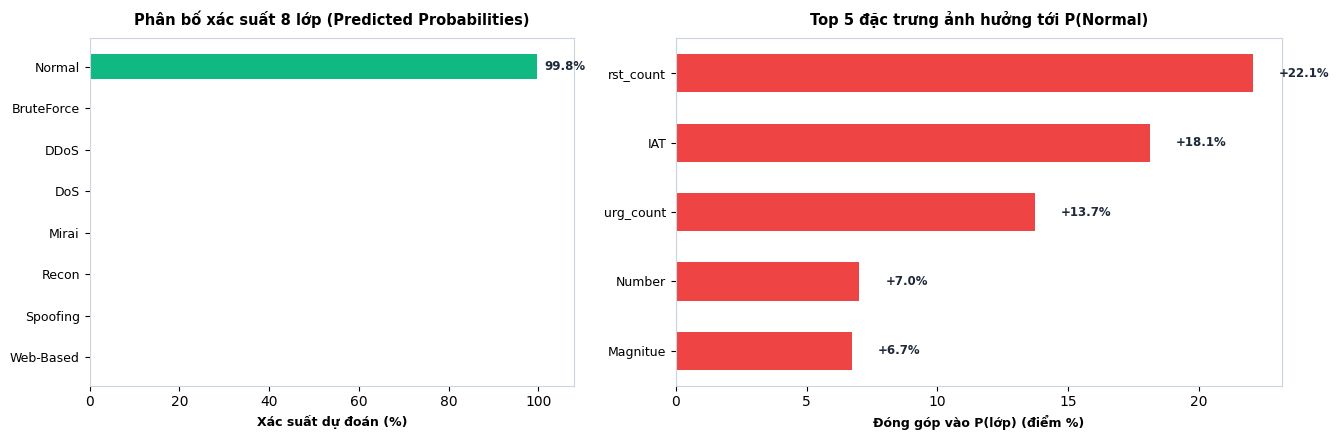

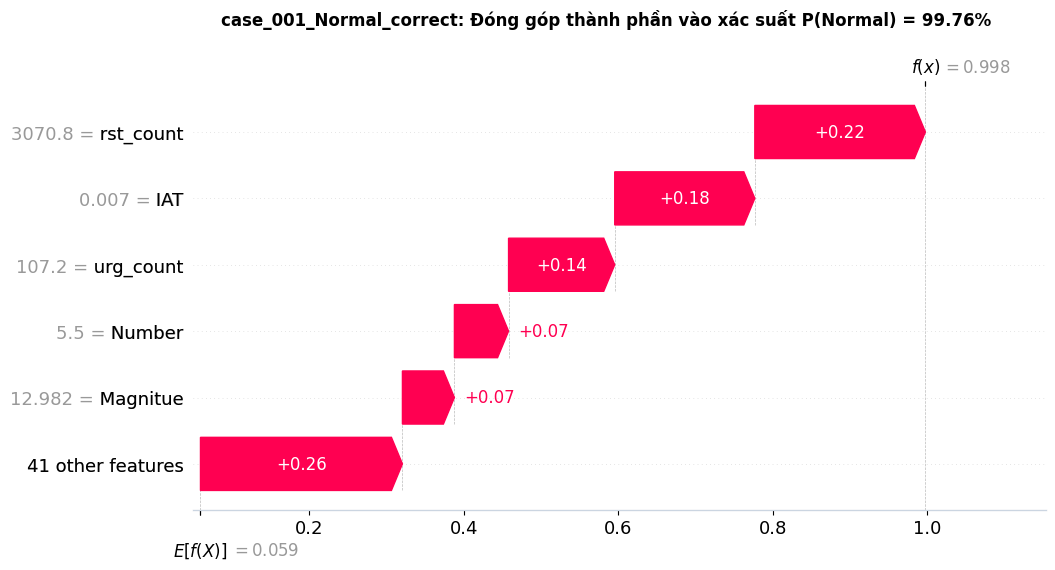


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 2/16: case_002_Normal_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: Normal       | Dự đoán: Recon (78.93%)
    Xác suất nền: 0.0011 | Tổng tác động SHAP: +0.7882
    Thời gian tính toán: 0.75 s | Sai số Additivity: 3.33e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,Magnitue,62.53,False,+0.0976,+9.76%,Increase
1,2,Header_Length,1.141e+06,False,+0.0948,+9.48%,Increase
2,3,Srate,"2,135",False,+0.0766,+7.66%,Increase
3,4,urg_count,141,False,+0.0749,+7.49%,Increase
4,5,Protocol Type,6,False,+0.0702,+7.02%,Increase


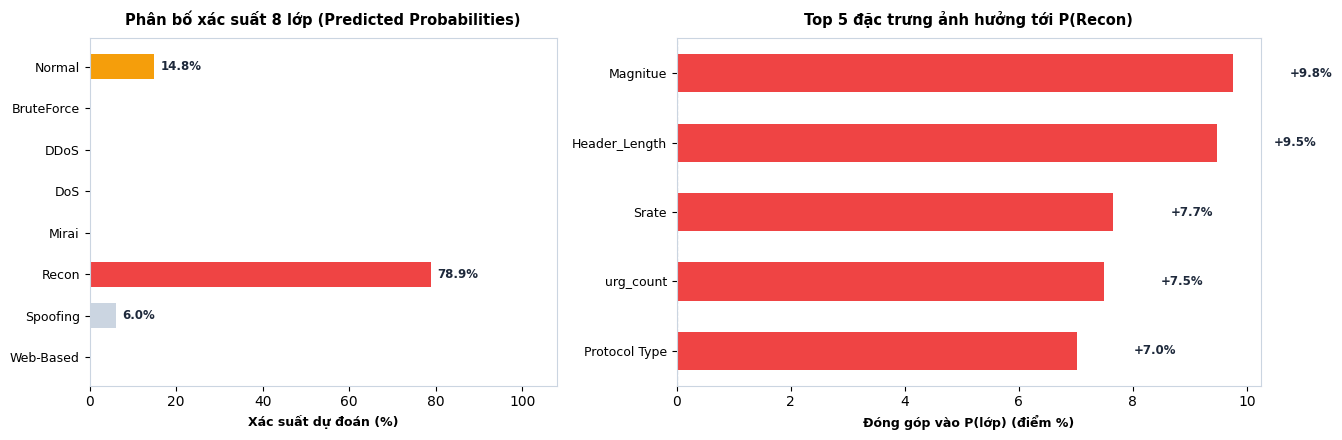

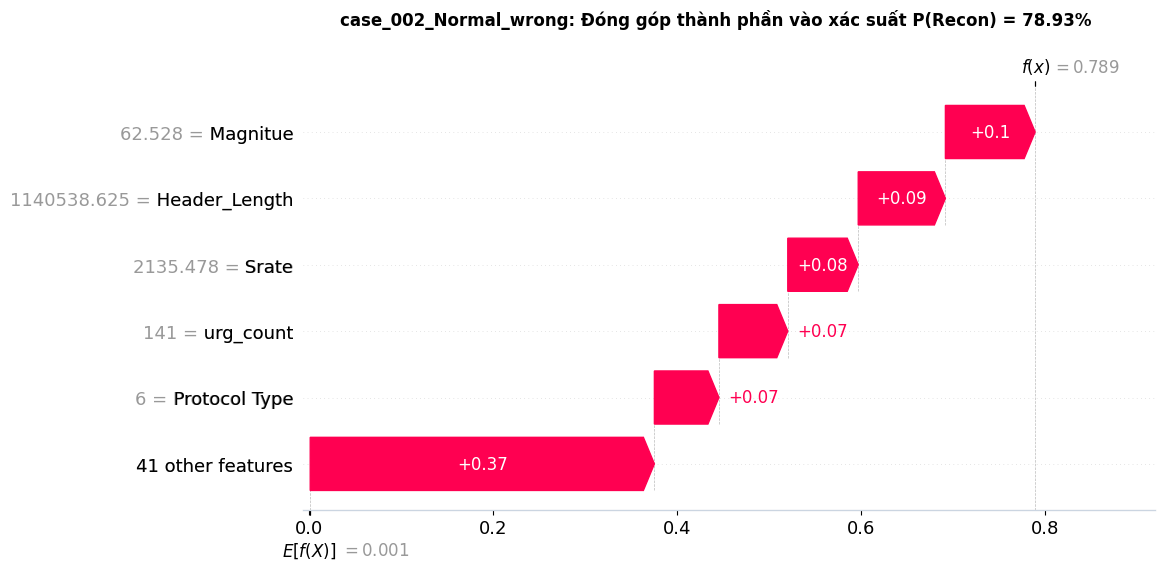


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 3/16: case_003_BruteForce_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: BruteForce   | Dự đoán: BruteForce (49.54%)
    Xác suất nền: 0.0001 | Tổng tác động SHAP: +0.4953
    Thời gian tính toán: 0.77 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,rst_count,"1,465",False,+0.2382,+23.82%,Increase
1,2,Protocol Type,6,False,+0.0634,+6.34%,Increase
2,3,Magnitue,26.94,False,+0.0611,+6.11%,Increase
3,4,IAT,0.009247,False,+0.0582,+5.82%,Increase
4,5,Tot size,193.4,False,-0.0445,-4.45%,Decrease


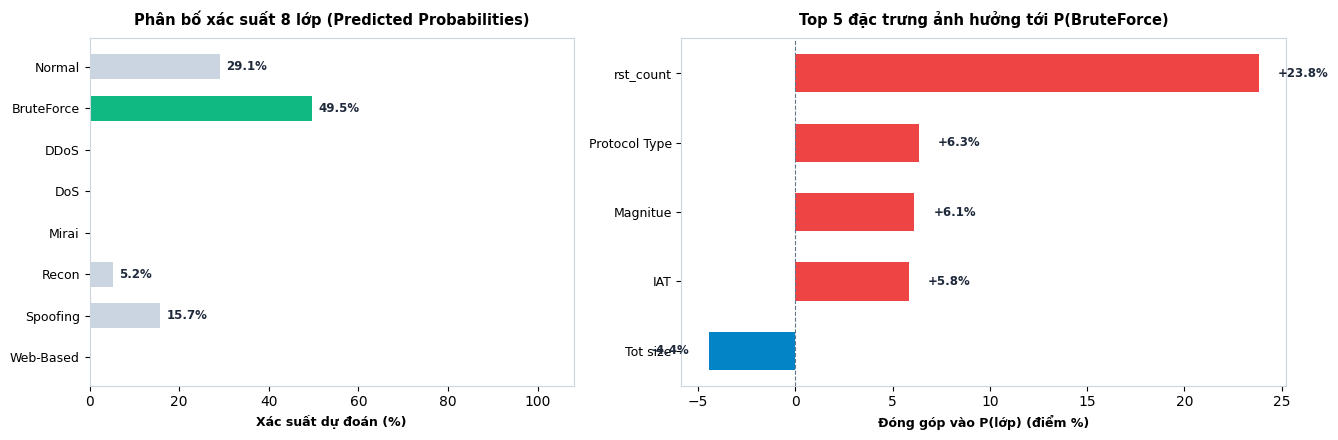

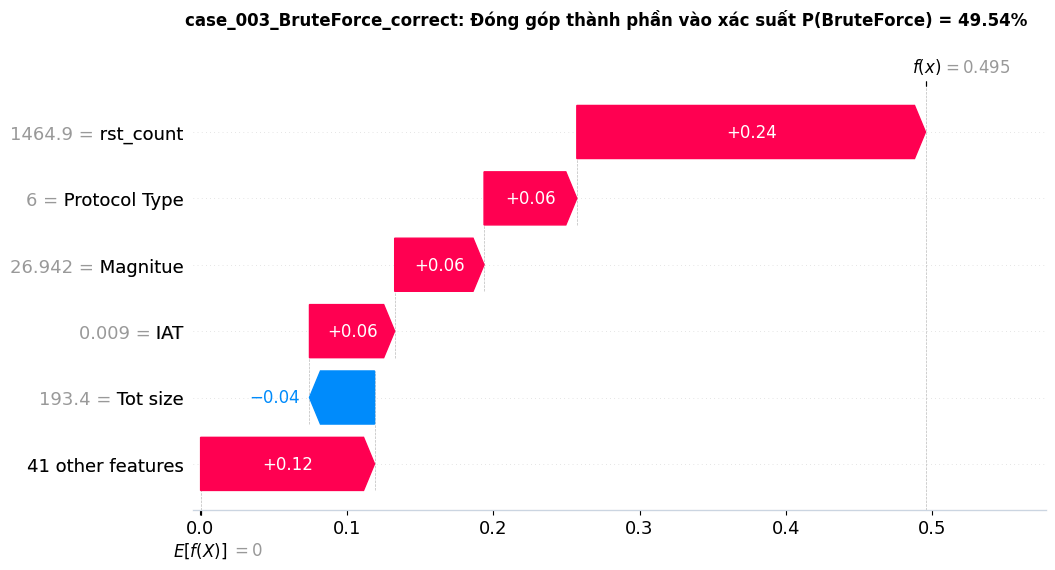


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 4/16: case_004_BruteForce_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: BruteForce   | Dự đoán: Spoofing (54.19%)
    Xác suất nền: 0.0020 | Tổng tác động SHAP: +0.5399
    Thời gian tính toán: 0.76 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,0.003423,False,+0.1473,+14.73%,Increase
1,2,Number,5.5,False,+0.1342,+13.42%,Increase
2,3,Magnitue,27.13,False,+0.0698,+6.98%,Increase
3,4,Header_Length,4.58e+04,False,+0.0489,+4.89%,Increase
4,5,Weight,38.5,False,+0.0433,+4.33%,Increase


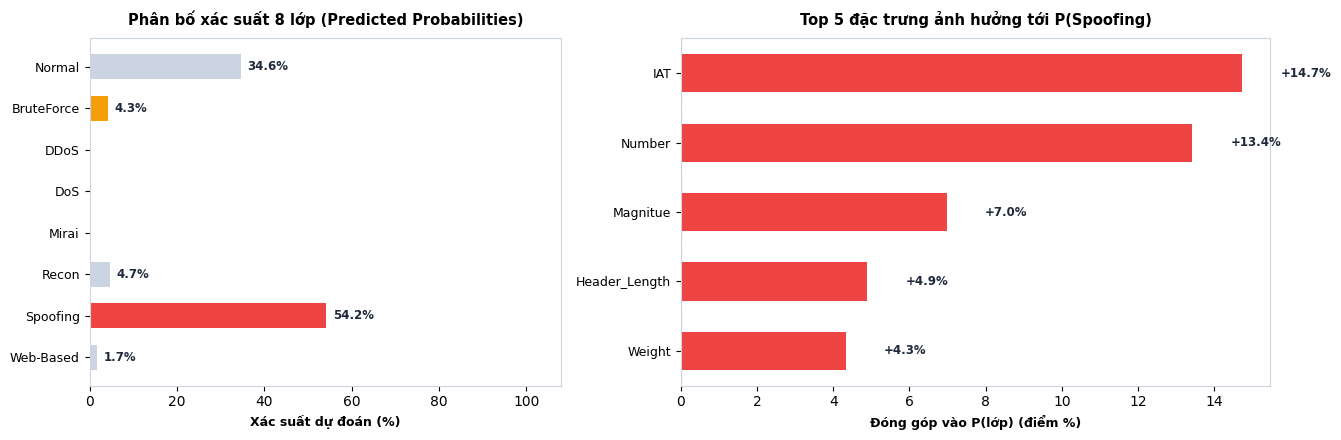

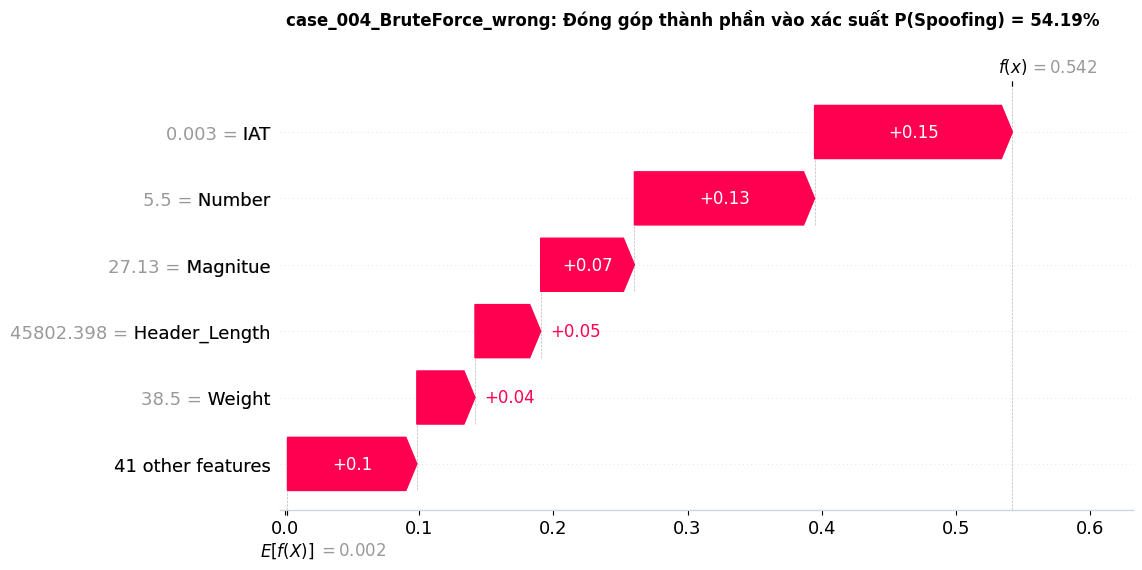


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 5/16: case_005_DDoS_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: DDoS         | Dự đoán: DDoS (100.00%)
    Xác suất nền: 0.6251 | Tổng tác động SHAP: +0.3749
    Thời gian tính toán: 0.61 s | Sai số Additivity: 6.94e-18
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,8.31e+07,False,+0.2876,+28.76%,Increase
1,2,Min,50,False,+0.0353,+3.53%,Increase
2,3,Magnitue,10,False,+0.0136,+1.36%,Increase
3,4,Tot sum,525,False,+0.0100,+1.00%,Increase
4,5,Number,9.5,False,+0.0077,+0.77%,Increase


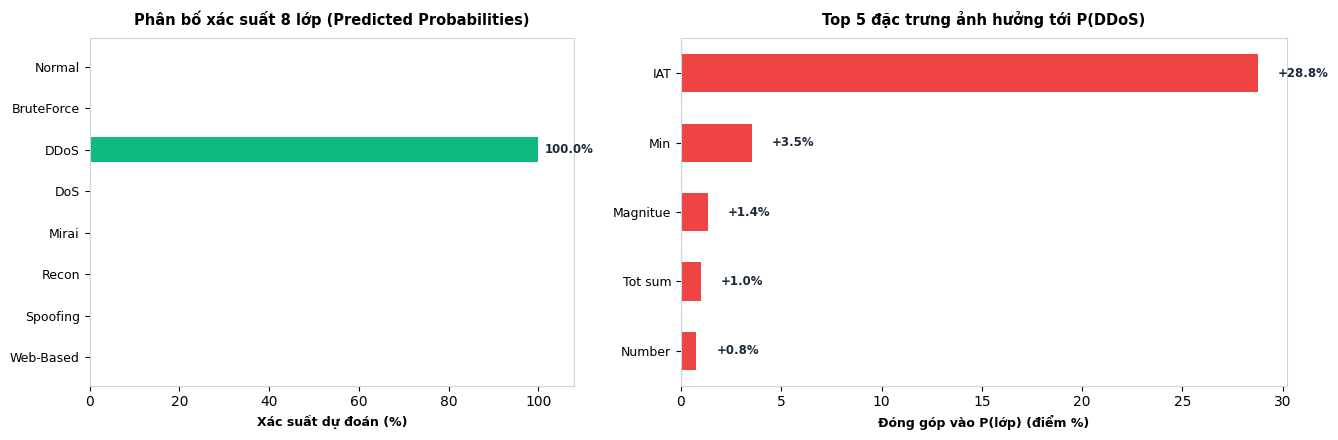

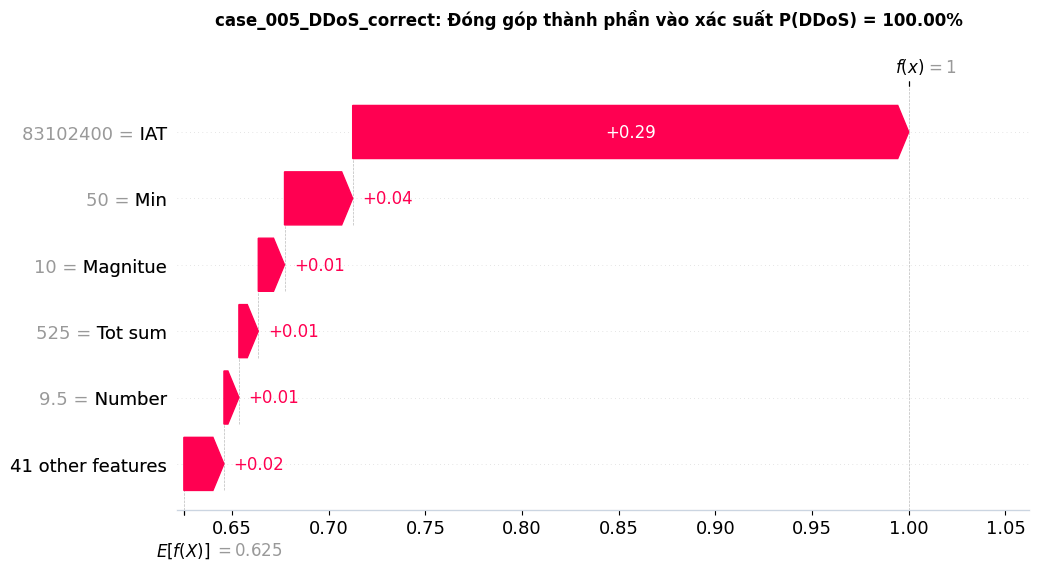


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 6/16: case_006_DDoS_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: DDoS         | Dự đoán: DoS (87.23%)
    Xác suất nền: 0.2188 | Tổng tác động SHAP: +0.6536
    Thời gian tính toán: 0.66 s | Sai số Additivity: 1.95e-18
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,5.652e+07,False,+0.4680,+46.80%,Increase
1,2,Weight,137.8,False,-0.1542,-15.42%,Decrease
2,3,Rate,0.2171,False,+0.1205,+12.05%,Increase
3,4,Header_Length,108,False,+0.1139,+11.39%,Increase
4,5,Variance,0,False,+0.0475,+4.75%,Increase


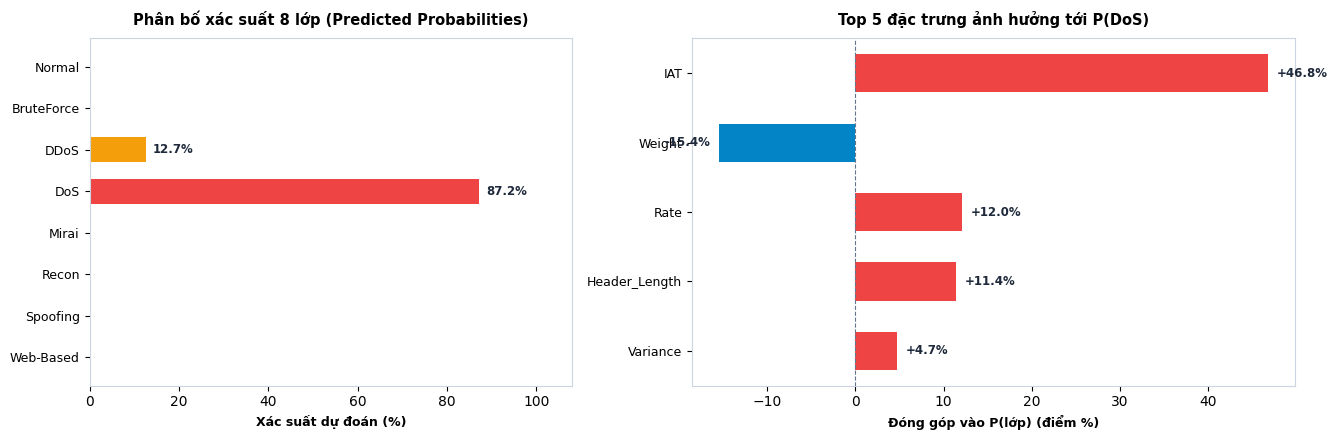

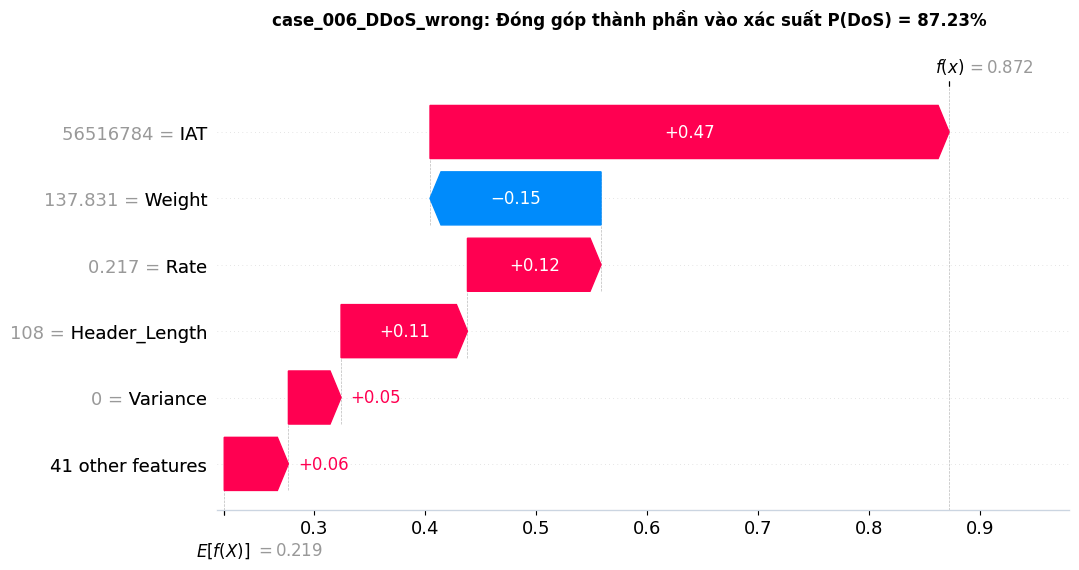


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 7/16: case_007_DoS_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: DoS          | Dự đoán: DoS (100.00%)
    Xác suất nền: 0.2188 | Tổng tác động SHAP: +0.7812
    Thời gian tính toán: 0.58 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,8.294e+07,False,+0.7193,+71.93%,Increase
1,2,Magnitue,10.39,False,+0.0119,+1.19%,Increase
2,3,Weight,141.6,False,+0.0091,+0.91%,Increase
3,4,Number,9.5,False,+0.0091,+0.91%,Increase
4,5,Tot sum,567,False,+0.0071,+0.71%,Increase


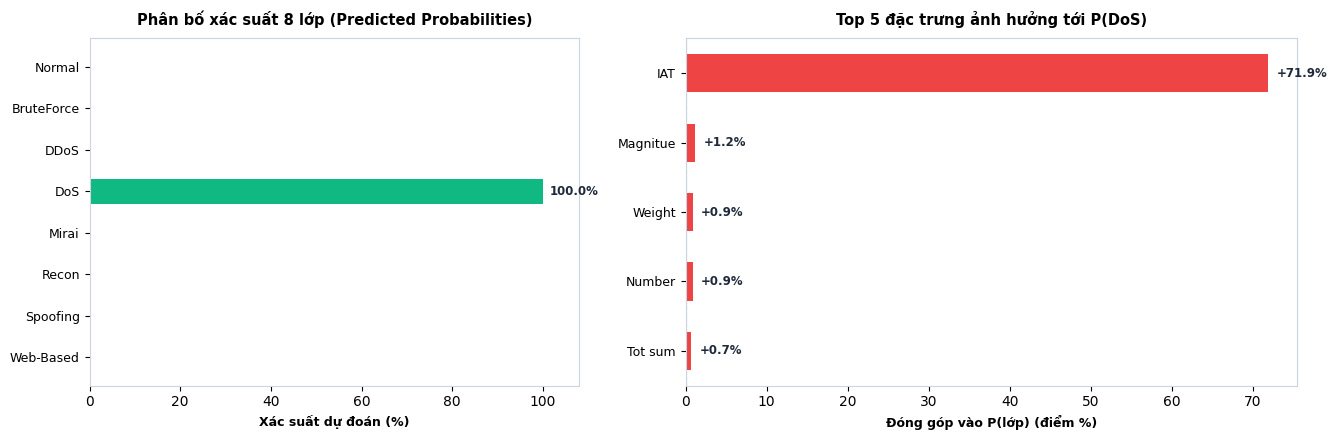

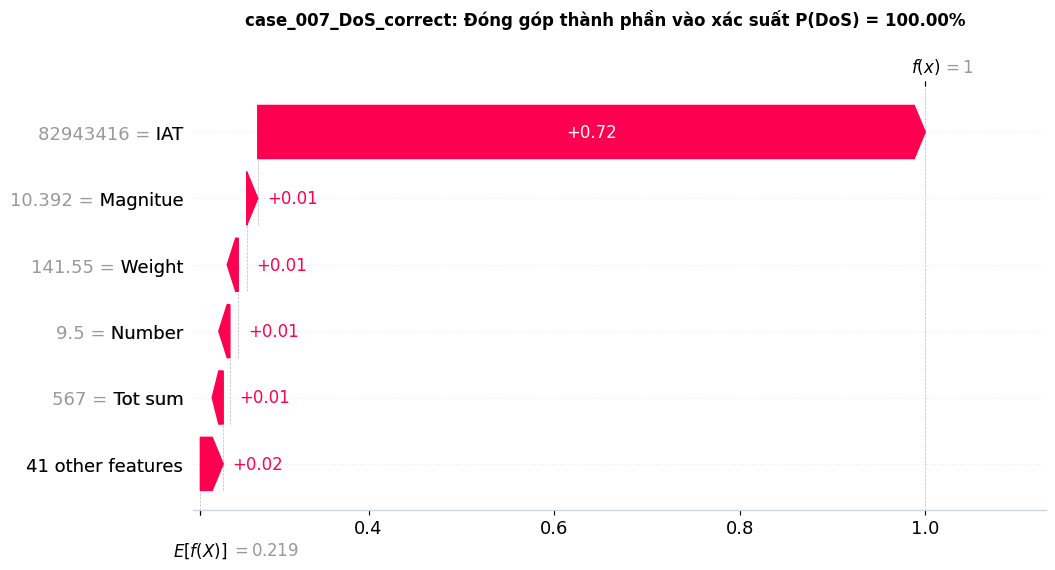


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 8/16: case_008_DoS_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: DoS          | Dự đoán: DDoS (63.98%)
    Xác suất nền: 0.6251 | Tổng tác động SHAP: +0.0147
    Thời gian tính toán: 0.64 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,4.239e-06,False,-0.2418,-24.18%,Decrease
1,2,Weight,31.67,False,+0.2236,+22.36%,Increase
2,3,Srate,"9,621",False,-0.0549,-5.49%,Decrease
3,4,Header_Length,2.405e+04,False,-0.0480,-4.80%,Decrease
4,5,Magnitue,10,False,+0.0460,+4.60%,Increase


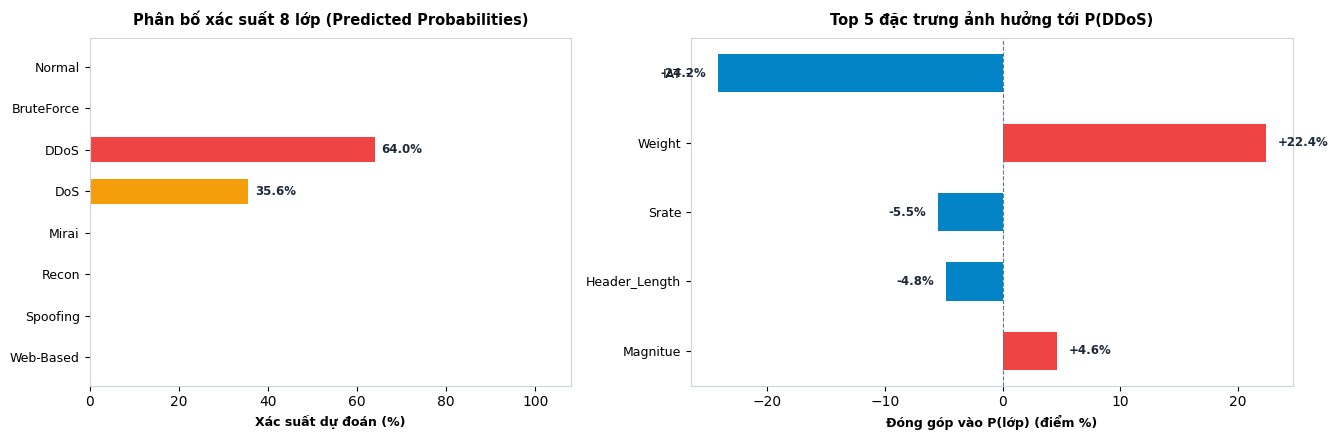

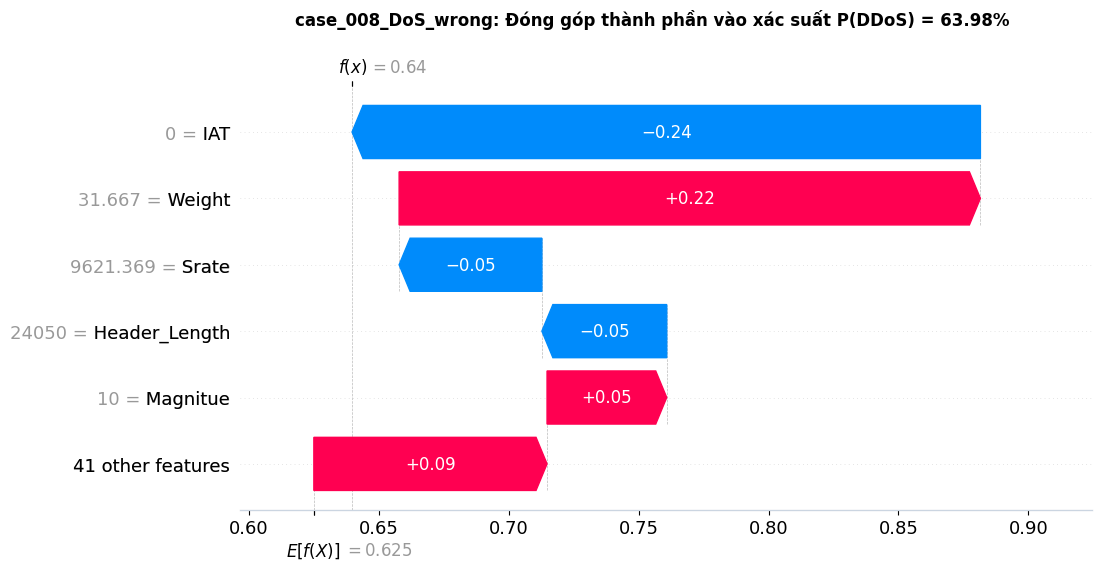


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 9/16: case_009_Mirai_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: Mirai        | Dự đoán: Mirai (99.99%)
    Xác suất nền: 0.0938 | Tổng tác động SHAP: +0.9062
    Thời gian tính toán: 0.70 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,Magnitue,32.93,False,+0.2008,+20.08%,Increase
1,2,Min,448.5,False,+0.1166,+11.66%,Increase
2,3,IAT,8.371e+07,False,+0.1099,+10.99%,Increase
3,4,Protocol Type,16.83,False,+0.0963,+9.63%,Increase
4,5,Max,554,False,+0.0689,+6.89%,Increase


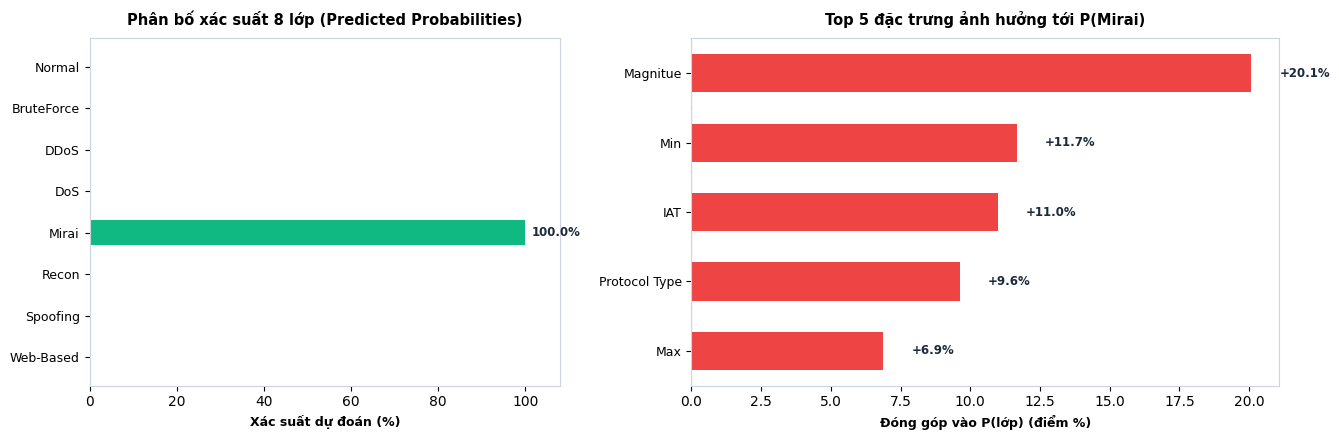

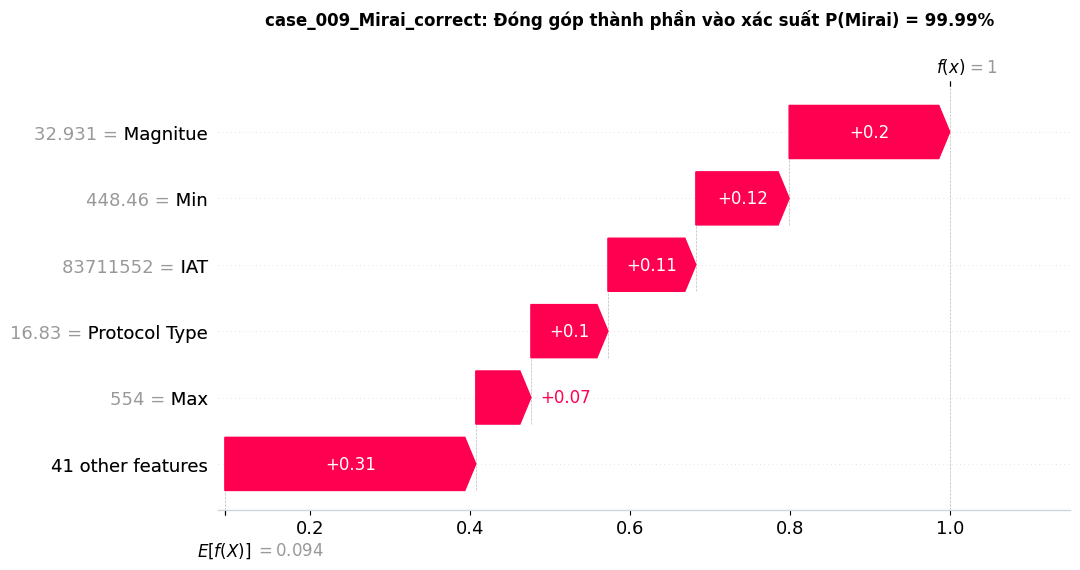


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 10/16: case_010_Mirai_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: Mirai        | Dự đoán: Normal (33.32%)
    Xác suất nền: 0.0592 | Tổng tác động SHAP: +0.2740
    Thời gian tính toán: 0.76 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,7.604e+07,False,+0.0545,+5.45%,Increase
1,2,Magnitue,35.39,False,+0.0373,+3.73%,Increase
2,3,HTTPS,1,False,+0.0346,+3.46%,Increase
3,4,rst_count,209.8,False,+0.0343,+3.43%,Increase
4,5,Weight,130.1,False,+0.0315,+3.15%,Increase


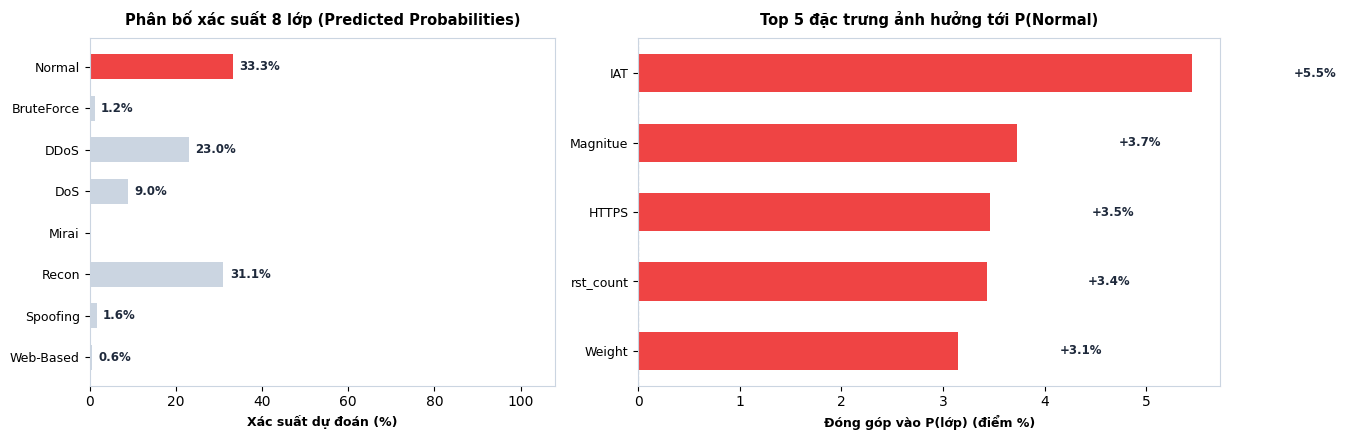

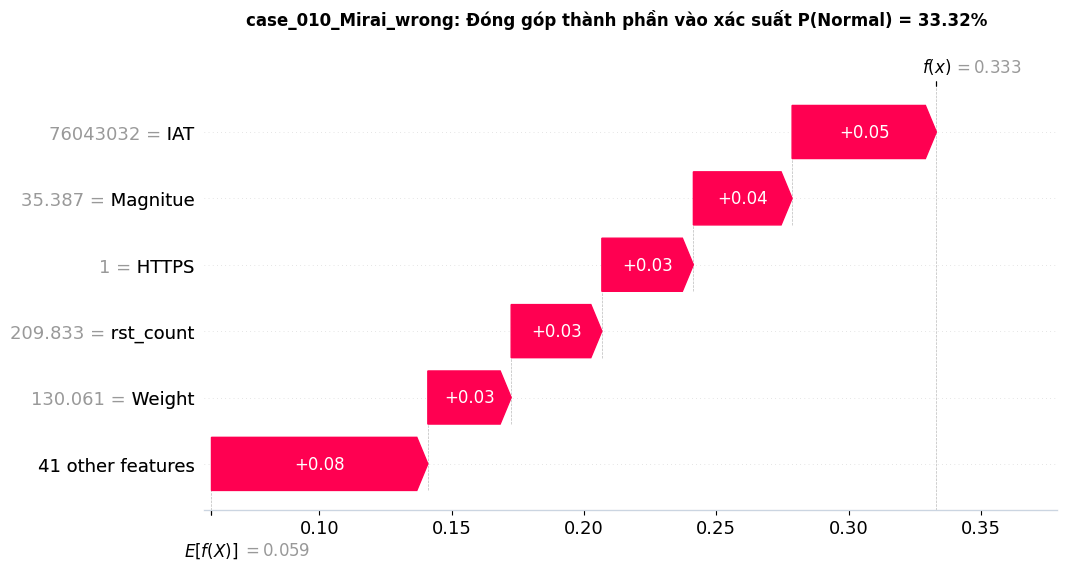


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 11/16: case_011_Recon_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: Recon        | Dự đoán: Recon (99.71%)
    Xác suất nền: 0.0011 | Tổng tác động SHAP: +0.9960
    Thời gian tính toán: 0.72 s | Sai số Additivity: 2.78e-17
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,1.668e+08,False,+0.5091,+50.91%,Increase
1,2,Number,13.5,False,+0.1652,+16.52%,Increase
2,3,syn_count,0.6,False,+0.0624,+6.24%,Increase
3,4,Protocol Type,10.4,False,+0.0494,+4.94%,Increase
4,5,Duration,95.2,False,+0.0342,+3.42%,Increase


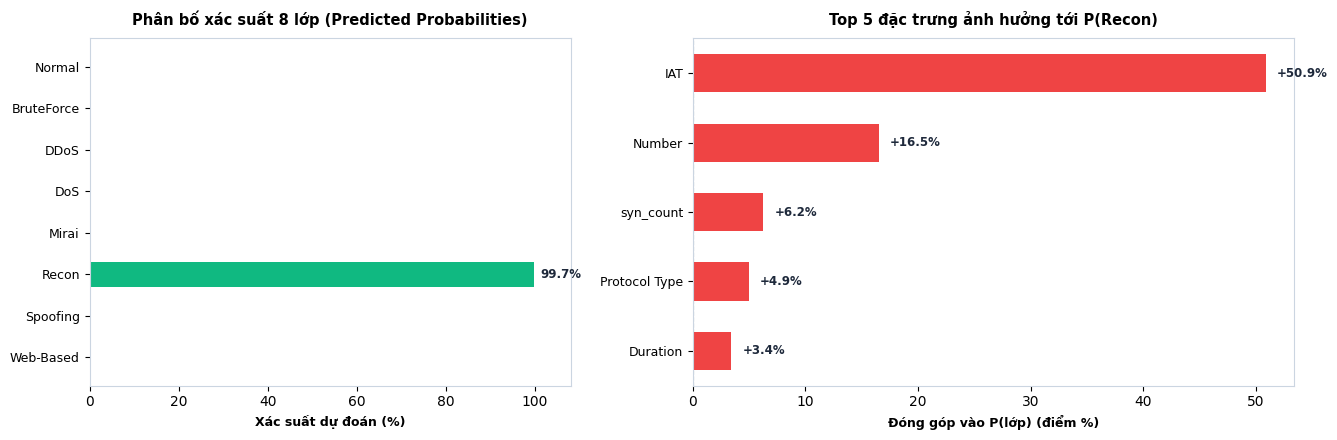

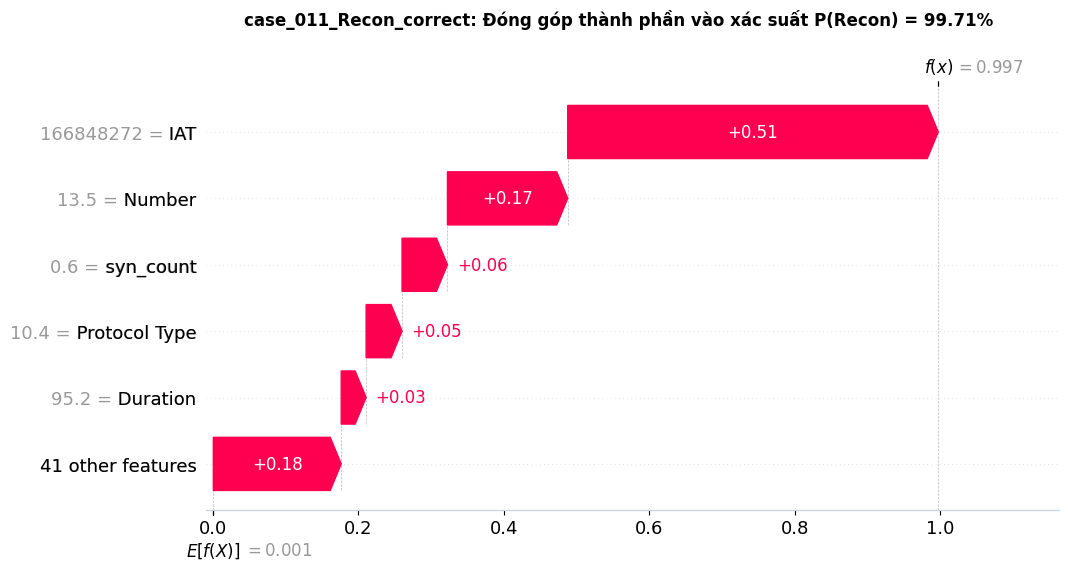


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 12/16: case_012_Recon_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: Recon        | Dự đoán: Spoofing (49.65%)
    Xác suất nền: 0.0020 | Tổng tác động SHAP: +0.4945
    Thời gian tính toán: 0.75 s | Sai số Additivity: 5.55e-17
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,0.003921,False,+0.1608,+16.08%,Increase
1,2,Number,5.5,False,+0.1258,+12.58%,Increase
2,3,flow_duration,343.3,False,+0.0368,+3.68%,Increase
3,4,Weight,38.5,False,+0.0353,+3.53%,Increase
4,5,AVG,88.24,False,+0.0328,+3.28%,Increase


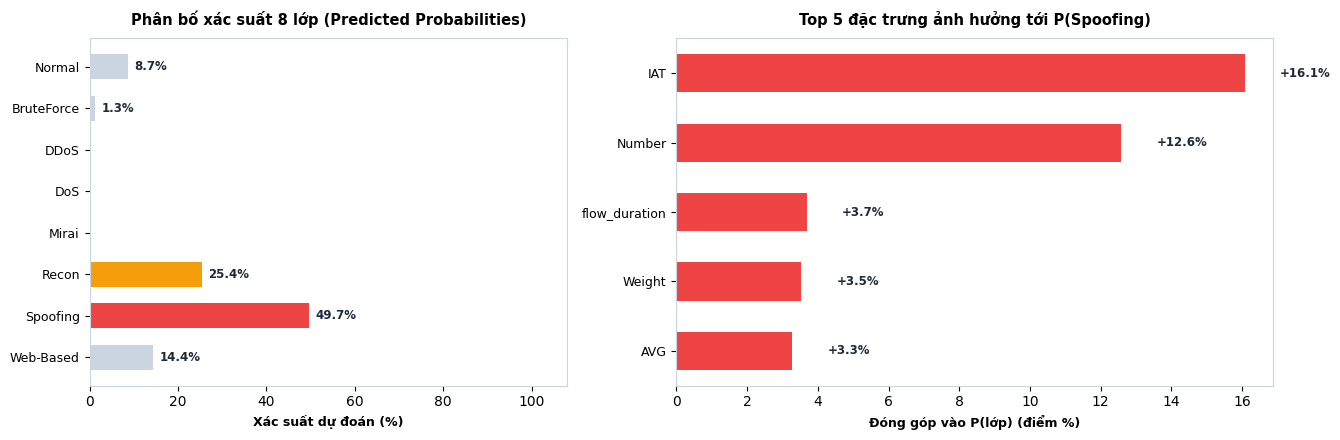

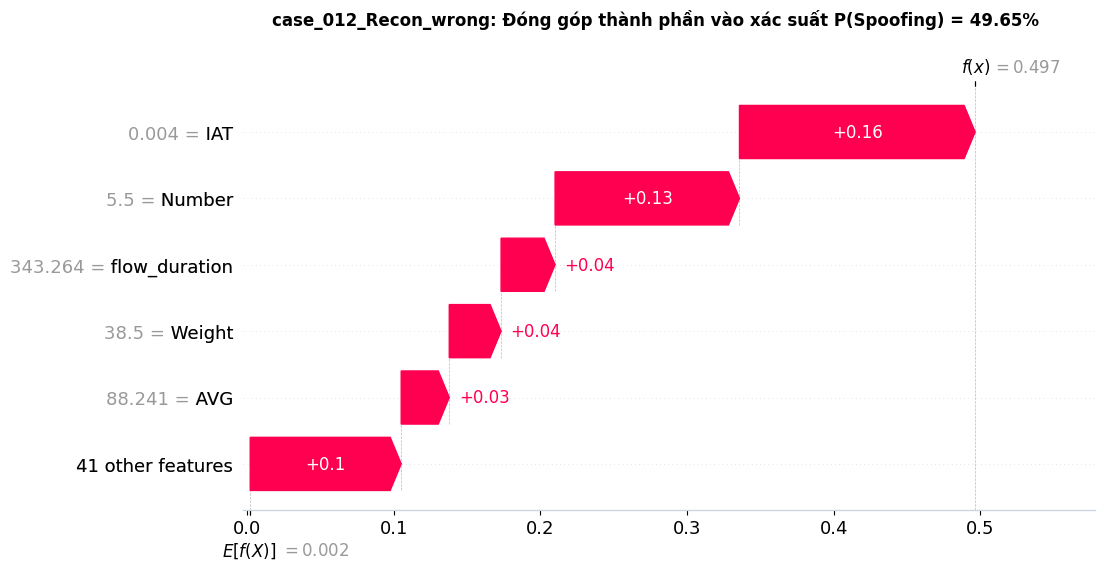


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 13/16: case_013_Spoofing_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: Spoofing     | Dự đoán: Spoofing (99.89%)
    Xác suất nền: 0.0020 | Tổng tác động SHAP: +0.9969
    Thời gian tính toán: 0.73 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,1.669e+08,False,+0.6479,+64.79%,Increase
1,2,Protocol Type,6,False,+0.1162,+11.62%,Increase
2,3,Number,13.5,False,+0.0775,+7.75%,Increase
3,4,Header_Length,1.516e+06,False,+0.0423,+4.23%,Increase
4,5,Radius,"1,466",False,+0.0310,+3.10%,Increase


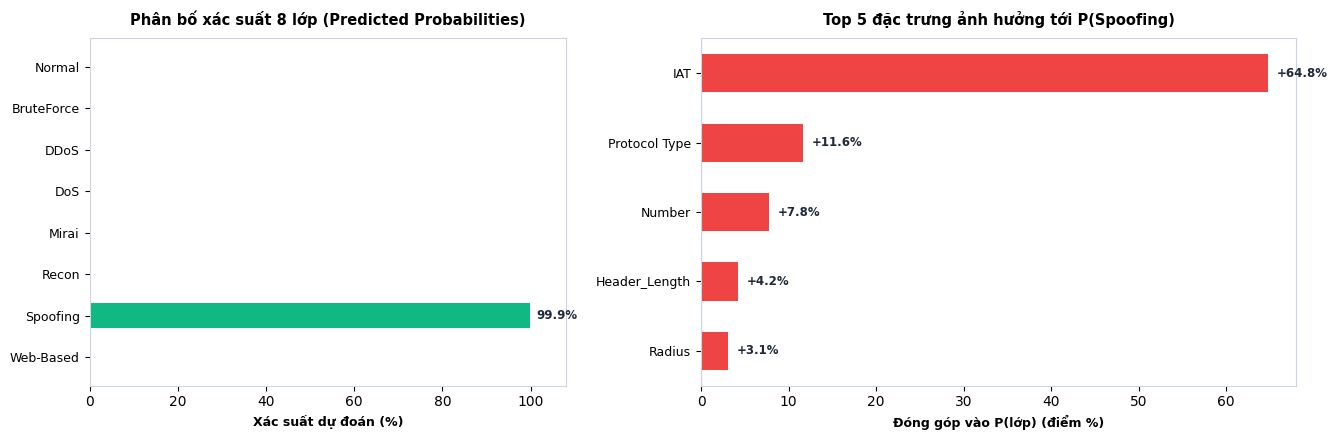

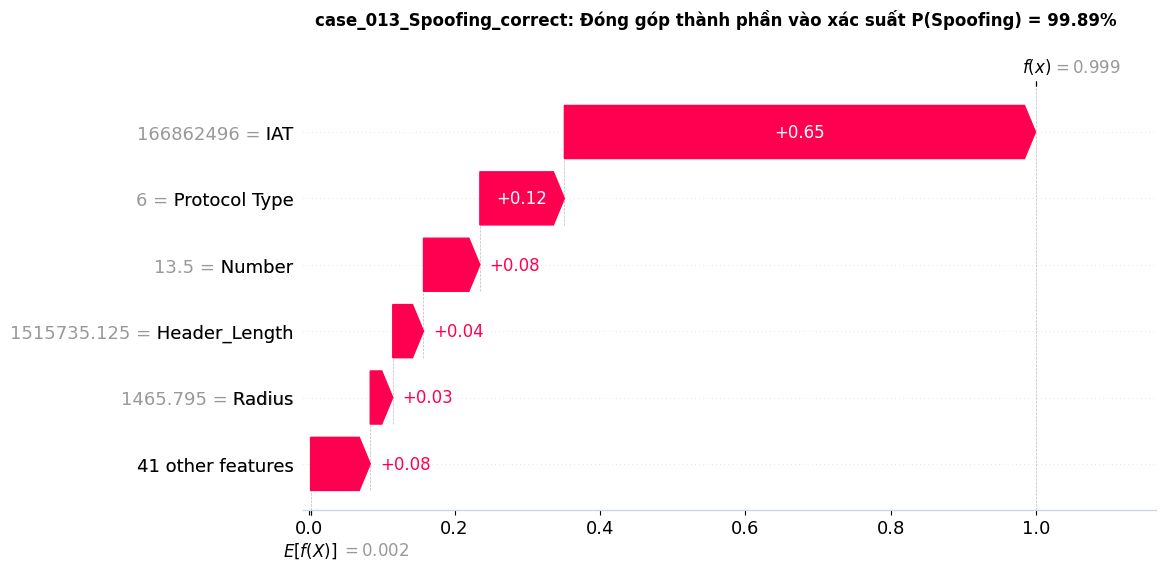


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 14/16: case_014_Spoofing_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: Spoofing     | Dự đoán: Normal (39.83%)
    Xác suất nền: 0.0592 | Tổng tác động SHAP: +0.3391
    Thời gian tính toán: 0.76 s | Sai số Additivity: 5.55e-17
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,Magnitue,15.49,False,+0.0698,+6.98%,Increase
1,2,Number,5.5,False,+0.0574,+5.74%,Increase
2,3,IAT,0.004654,False,+0.0558,+5.58%,Increase
3,4,syn_count,1.6,False,-0.0522,-5.22%,Decrease
4,5,Variance,0.9,False,+0.0284,+2.84%,Increase


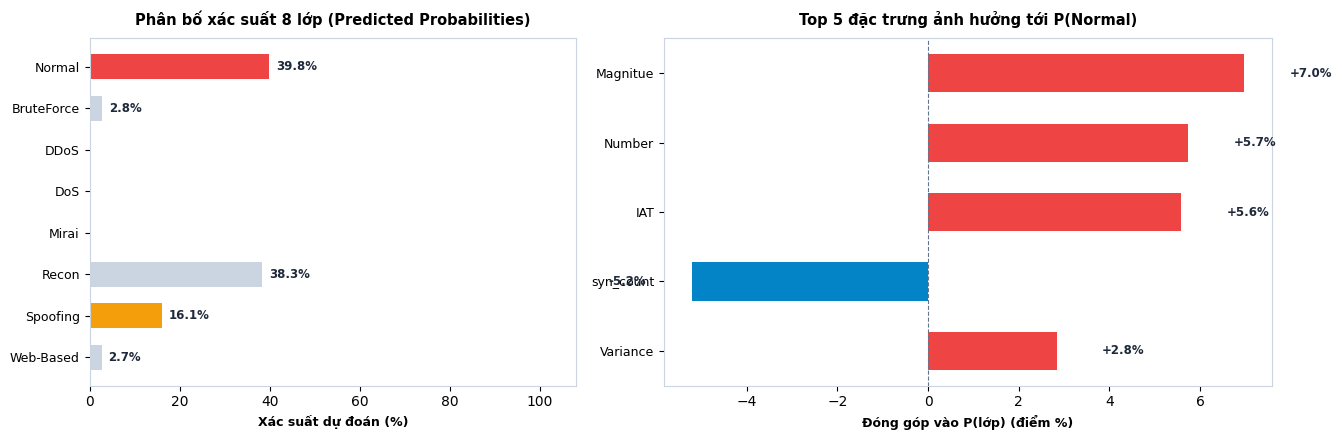

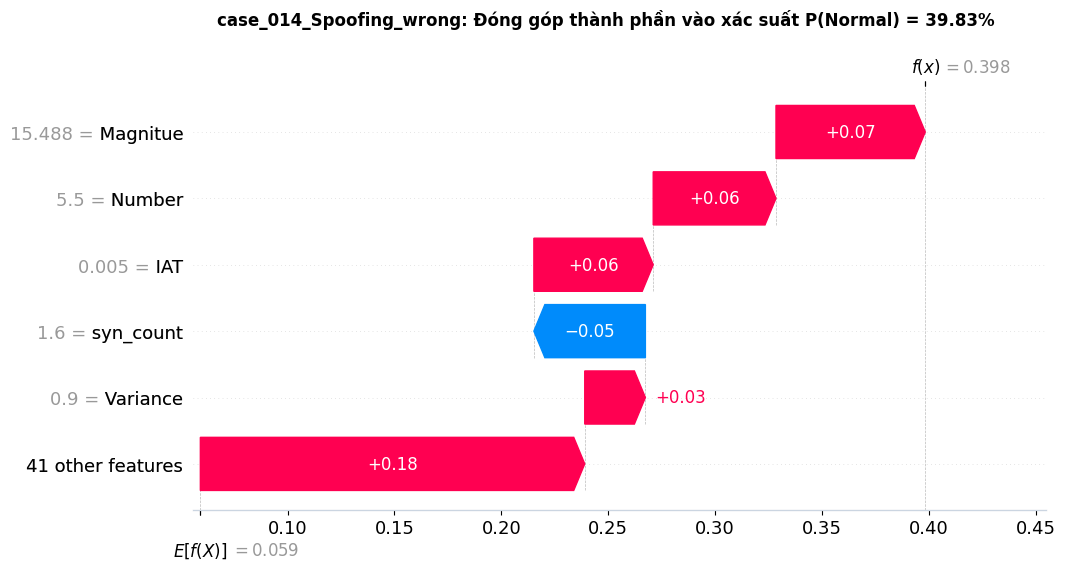


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 15/16: case_015_Web-Based_correct
    Trạng thái: ✅ DỰ ĐOÁN CHÍNH XÁC (CORRECT)
    Thực tế: Web-Based    | Dự đoán: Web-Based (98.75%)
    Xác suất nền: 0.0000 | Tổng tác động SHAP: +0.9875
    Thời gian tính toán: 0.76 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,IAT,1.665e+08,False,+0.2352,+23.52%,Increase
1,2,Magnitue,19.56,False,+0.1821,+18.21%,Increase
2,3,Protocol Type,5.5,False,+0.0997,+9.97%,Increase
3,4,Number,13.5,False,+0.0835,+8.35%,Increase
4,5,Tot size,236.5,False,+0.0602,+6.02%,Increase


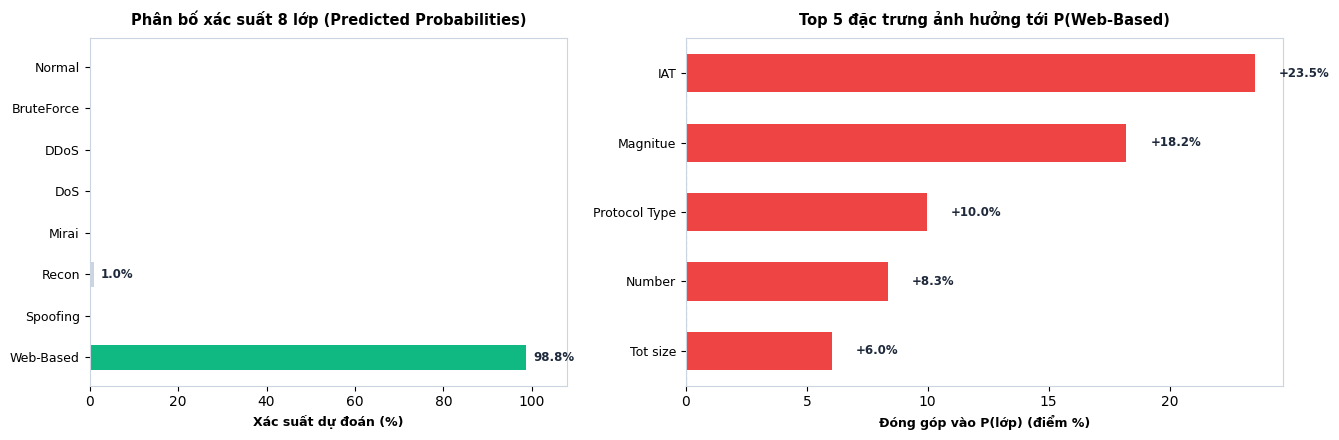

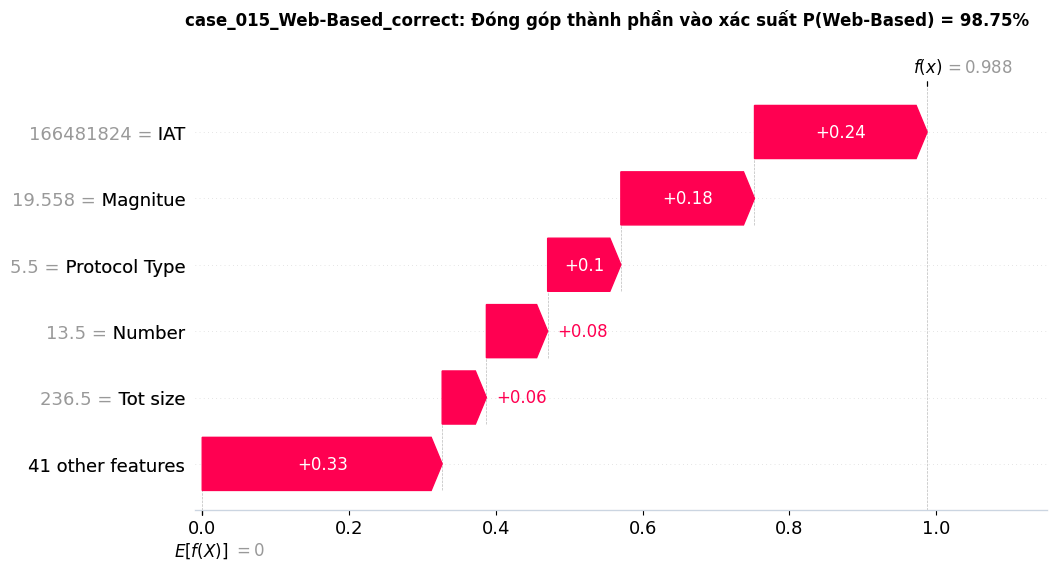


══════════════════════════════════════════════════════════════════════════════
 🔬 CA GIẢI THÍCH 16/16: case_016_Web-Based_wrong
    Trạng thái: ⚠️ DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)
    Thực tế: Web-Based    | Dự đoán: Recon (47.20%)
    Xác suất nền: 0.0011 | Tổng tác động SHAP: +0.4709
    Thời gian tính toán: 0.73 s | Sai số Additivity: 1.11e-16
══════════════════════════════════════════════════════════════════════════════


/tmp/ipykernel_208/17931268.py:153: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  }).applymap(


,Rank,Feature,Value,Missing,SHAP,Impact (percentage points),Direction
0,1,Number,5.5,False,+0.0965,+9.65%,Increase
1,2,IAT,0.01711,False,+0.0615,+6.15%,Increase
2,3,Variance,0.9,False,+0.0587,+5.87%,Increase
3,4,flow_duration,158.9,False,+0.0587,+5.87%,Increase
4,5,Weight,38.5,False,+0.0511,+5.11%,Increase


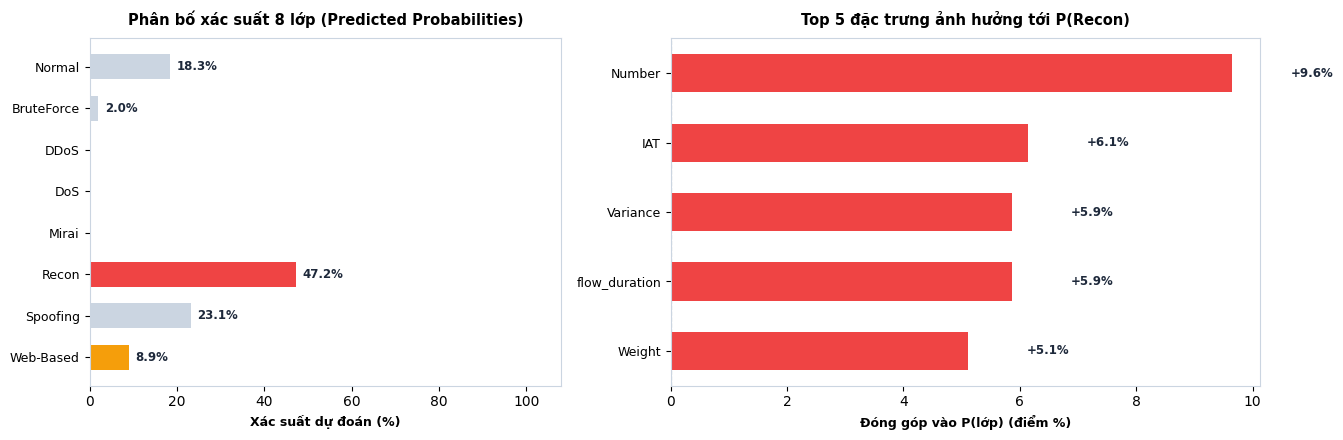

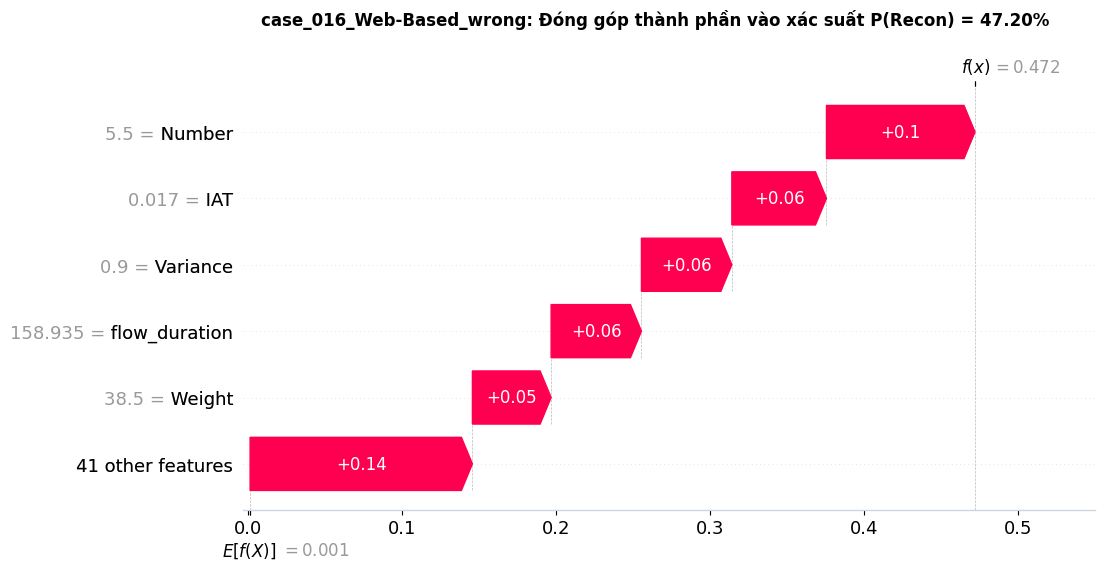

In [10]:
if sha256_file(OUTPUT_DIR / "protocol.json") != PROTOCOL_SHA256:
    raise RuntimeError("Protocol thay đổi trước khi chạy SHAP.")
CASES_DIR = OUTPUT_DIR / "cases"
CASES_DIR.mkdir(exist_ok=False)
case_results = []
top_feature_records = []

for case_number, row in case_table.iterrows():
    case_id = row["case_id"]
    case_directory = CASES_DIR / case_id
    case_directory.mkdir()
    sample = case_values[case_number:case_number + 1]
    true_id = int(row["class_id"])
    predicted_id = int(case_probabilities[case_number].argmax())

    started = time.perf_counter()
    explanation, probabilities, errors = explain_one_sample(sample, int(row["shap_seed"]))
    shap_seconds = time.perf_counter() - started
    np.testing.assert_allclose(probabilities, case_probabilities[case_number], rtol=1e-6, atol=1e-7)
    if int(probabilities.argmax()) != predicted_id:
        raise ValueError("Nhãn trong bước SHAP khác dự đoán đã kiểm chứng.")
    contributions = explanation.values[0]
    base_values = explanation.base_values[0]
    class_contributions = contributions[:, predicted_id]
    ordered_features = np.argsort(-np.abs(class_contributions), kind="stable")
    top_indices = ordered_features[:TOP_FEATURES]

    feature_table = pd.DataFrame({
        "Feature": feature_names, "Value": sample[0], "Missing": np.isnan(sample[0]),
        "SHAP": class_contributions, "Impact (percentage points)": class_contributions * 100,
    })
    feature_table["Direction"] = np.where(class_contributions > 0, "Increase", "Decrease")
    feature_table.loc[class_contributions == 0, "Direction"] = "No change"
    feature_table = feature_table.iloc[ordered_features].reset_index(drop=True)
    feature_table.insert(0, "Rank", np.arange(1, len(feature_names) + 1))
    feature_table.to_csv(case_directory / "all_features_predicted_class.csv", index=False)
    top_table = feature_table.head(TOP_FEATURES).copy()
    top_table.to_csv(case_directory / "top5_features.csv", index=False)

    # Giữ SHAP đủ 8 lớp để có thể kiểm tra lại hoặc đổi lớp cần xem.
    all_classes = pd.DataFrame(contributions, columns=CLASS_NAMES)
    all_classes.insert(0, "Feature", feature_names)
    all_classes.insert(1, "Value", sample[0])
    all_classes.to_csv(case_directory / "shap_all_classes.csv", index=False)
    np.savez_compressed(
        case_directory / "shap_values.npz", values=contributions, base_values=base_values,
        input_values=sample[0], probabilities=probabilities,
        feature_names=np.asarray(feature_names), class_names=np.asarray(CLASS_NAMES),
    )

    if true_id != predicted_id:
        comparison_id = true_id
        comparison_reason = "true class for a misclassified sample"
    else:
        comparison_id = int(np.argsort(-probabilities, kind="stable")[1])
        comparison_reason = "second-highest predicted probability"
    margin_values = contributions[:, predicted_id] - contributions[:, comparison_id]
    base_margin = float(base_values[predicted_id] - base_values[comparison_id])
    probability_margin = float(probabilities[predicted_id] - probabilities[comparison_id])
    np.testing.assert_allclose(base_margin + margin_values.sum(), probability_margin, rtol=0, atol=2 * ADDITIVITY_TOLERANCE)
    margin_order = np.argsort(-np.abs(margin_values), kind="stable")
    pd.DataFrame({
        "Feature": np.asarray(feature_names)[margin_order], "Value": sample[0, margin_order],
        "SHAP probability-gap contribution": margin_values[margin_order],
    }).to_csv(case_directory / "comparison_features.csv", index=False)

    top_features = []
    for rank, feature_index in enumerate(top_indices, start=1):
        value = float(sample[0, feature_index])
        shap_value = float(class_contributions[feature_index])
        if shap_value > 0:
            direction = "increase"
        elif shap_value < 0:
            direction = "decrease"
        else:
            direction = "no_change"
        item = {
            "rank": rank, "feature": feature_names[feature_index],
            "value": None if np.isnan(value) else value, "missing": bool(np.isnan(value)),
            "shap_value": shap_value, "impact_percentage_points": shap_value * 100,
            "direction": direction,
        }
        top_features.append(item)
        feature_record = item.copy()
        feature_record["case_id"] = case_id
        feature_record["explained_class"] = CLASS_NAMES[predicted_id]
        top_feature_records.append(feature_record)

    payload = {
        "case_id": case_id, "model_id": MODEL_ID, "source_xgb_run_id": SOURCE_RUN_ID,
        "data_run_id": DATA_RUN_ID, "validation_row_index": int(row["validation_row_index"]),
        "source_split": str(row["source_split"]), "source_row_index": int(row["source_row_index"]),
        "original_label": str(row["original_label"]), "true_class": CLASS_NAMES[true_id],
        "predicted_class": CLASS_NAMES[predicted_id], "correct": bool(true_id == predicted_id),
        "probabilities": {name: float(probabilities[i]) for i, name in enumerate(CLASS_NAMES)},
        "explained_class": CLASS_NAMES[predicted_id], "output_unit": "probability",
        "base_probability": float(base_values[predicted_id]),
        "predicted_probability": float(probabilities[predicted_id]),
        "shap_sum": float(class_contributions.sum()),
        "other_features_shap_sum": float(class_contributions.sum() - class_contributions[top_indices].sum()),
        "top_features": top_features,
        "comparison": {
            "class": CLASS_NAMES[comparison_id], "reason": comparison_reason,
            "probability": float(probabilities[comparison_id]),
            "base_probability_gap": base_margin, "predicted_probability_gap": probability_margin,
        },
        "max_additivity_error_all_classes": float(errors.max()),
        "seed": int(row["shap_seed"]), "max_evals": MAX_EVALS, "shap_seconds": shap_seconds,
        "interpretation": "Contributions relative to the saved train background; not causal evidence.",
    }
    write_json(case_directory / "explanation.json", payload)

    # Diễn giải dựa trên số liệu SHAP, không tự gán ý nghĩa như 'Rate cao gây tấn công'.
    lines = [
        f"Model dự đoán {CLASS_NAMES[predicted_id]} với xác suất {probabilities[predicted_id]:.2%}.",
        f"Nhãn thật: {CLASS_NAMES[true_id]}. Nhãn gốc: {row['original_label']}.",
        f"Mốc tham chiếu của lớp này trên background train: {base_values[predicted_id]:.6f}.",
        f"Mốc tham chiếu + tổng SHAP = {base_values[predicted_id]:.6f} + ({class_contributions.sum():.6f}) = {probabilities[predicted_id]:.6f}.",
        "Top đặc trưng theo độ lớn đóng góp vào xác suất lớp được dự đoán:",
    ]
    for feature in top_features:
        raw_value = "thiếu (pipeline tự xử lý)" if feature["missing"] else f"{feature['value']:.6g}"
        if feature["shap_value"] > 0:
            direction = "tăng"
        elif feature["shap_value"] < 0:
            direction = "giảm"
        else:
            direction = "không đổi"
        lines.append(
            f"- {feature['feature']} = {raw_value}: đóng góp {direction} "
            f"{abs(feature['impact_percentage_points']):.3f} điểm phần trăm so với mốc tham chiếu."
        )
    (case_directory / "explanation.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")

    # In banner thông tin ca giải thích rõ ràng, đẹp mắt
    is_correct = (true_id == predicted_id)
    status_icon = "✅" if is_correct else "⚠️"
    status_str = "DỰ ĐOÁN CHÍNH XÁC (CORRECT)" if is_correct else "DỰ ĐOÁN NHẦM LẪN (MISCLASSIFIED)"
    print("\n" + "═" * 78)
    print(f" 🔬 CA GIẢI THÍCH {case_number + 1}/{len(case_table)}: {case_id}")
    print(f"    Trạng thái: {status_icon} {status_str}")
    print(f"    Thực tế: {CLASS_NAMES[true_id]:<12} | Dự đoán: {CLASS_NAMES[predicted_id]} ({probabilities[predicted_id]:.2%})")
    print(f"    Xác suất nền: {base_values[predicted_id]:.4f} | Tổng tác động SHAP: {class_contributions.sum():+.4f}")
    print(f"    Thời gian tính toán: {shap_seconds:.2f} s | Sai số Additivity: {errors.max():.2e}")
    print("═" * 78)

    # Hiển thị bảng Top-5 đặc trưng có định dạng màu sắc trực quan
    styled_top = top_table.copy()
    styled_top_view = styled_top.style.format({
        "Value": lambda v: "Thiếu (NaN)" if np.isnan(v) else f"{v:,.4g}",
        "SHAP": "{:+.4f}",
        "Impact (percentage points)": "{:+.2f}%",
    }).applymap(
        lambda d: "background-color: #fee2e2; color: #991b1b; font-weight: bold;" if d == "Increase" 
        else ("background-color: #e0f2fe; color: #075985; font-weight: bold;" if d == "Decrease" else ""),
        subset=["Direction"]
    )
    display(styled_top_view)

    # Đồ thị 1: Biểu đồ chẩn đoán kép (Phân bố xác suất 8 lớp + Top 5 SHAP impact)
    fig_diag, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1, 1.25]})
    
    # Subplot 1: Phân bố xác suất 8 lớp
    bar_colors = ["#cbd5e1"] * len(CLASS_NAMES)
    bar_colors[predicted_id] = "#10b981" if is_correct else "#ef4444"
    if not is_correct:
        bar_colors[true_id] = "#f59e0b"
    
    y_pos = np.arange(len(CLASS_NAMES))
    ax1.barh(y_pos, probabilities * 100, color=bar_colors, edgecolor="none", height=0.6)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(CLASS_NAMES, fontsize=9, fontweight="500")
    ax1.invert_yaxis()
    ax1.set_xlabel("Xác suất dự đoán (%)", fontsize=9, fontweight="bold")
    ax1.set_title("Phân bố xác suất 8 lớp (Predicted Probabilities)", fontsize=10.5, fontweight="bold", pad=10)
    ax1.set_xlim(0, 108)
    for i, v in enumerate(probabilities):
        if v > 0.005:
            ax1.text(v * 100 + 1.5, i, f"{v * 100:.1f}%", va="center", fontsize=8.5, fontweight="bold", color="#1e293b")
    
    # Subplot 2: Top 5 đặc trưng ảnh hưởng mạnh nhất
    top_names = [top_features[i]["feature"] for i in range(len(top_features))]
    top_impacts = [top_features[i]["impact_percentage_points"] for i in range(len(top_features))]
    impact_colors = ["#ef4444" if imp > 0 else "#0284c7" for imp in top_impacts]
    y_top = np.arange(len(top_names))
    
    ax2.barh(y_top, top_impacts, color=impact_colors, edgecolor="none", height=0.55)
    ax2.set_yticks(y_top)
    ax2.set_yticklabels(top_names, fontsize=9, fontweight="500")
    ax2.invert_yaxis()
    ax2.axvline(0, color="#64748b", linestyle="--", linewidth=0.8)
    ax2.set_xlabel("Đóng góp vào P(lớp) (điểm %)", fontsize=9, fontweight="bold")
    ax2.set_title(f"Top 5 đặc trưng ảnh hưởng tới P({CLASS_NAMES[predicted_id]})", fontsize=10.5, fontweight="bold", pad=10)
    
    for i, imp in enumerate(top_impacts):
        offset = 1.0 if imp >= 0 else -1.0
        align = "left" if imp >= 0 else "right"
        ax2.text(imp + offset, i, f"{imp:+.1f}%", va="center", ha=align, fontsize=8.5, fontweight="bold", color="#1e293b")
        
    plt.tight_layout()
    fig_diag.savefig(case_directory / "case_diagnostic.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig_diag)

    # Đồ thị 2: Waterfall plot chính thức từ thư viện SHAP
    local_explanation = shap.Explanation(
        values=class_contributions, base_values=float(base_values[predicted_id]),
        data=sample[0], feature_names=feature_names,
    )
    shap.plots.waterfall(local_explanation, max_display=TOP_FEATURES + 1, show=False)
    figure = plt.gcf()
    figure.set_size_inches(11, 5.5)
    figure.suptitle(f"{case_id}: Đóng góp thành phần vào xác suất P({CLASS_NAMES[predicted_id]}) = {probabilities[predicted_id]:.2%}", fontsize=12, fontweight="bold", y=1.02)
    figure.savefig(case_directory / "waterfall.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(figure)

    case_results.append({
        "case_id": case_id, "true_class": CLASS_NAMES[true_id], "predicted_class": CLASS_NAMES[predicted_id],
        "correct": bool(true_id == predicted_id), "predicted_probability": float(probabilities[predicted_id]),
        "base_probability": float(base_values[predicted_id]), "shap_seconds": shap_seconds,
        "max_additivity_error_all_classes": float(errors.max()),
        "comparison_class": CLASS_NAMES[comparison_id], "prediction_gap": probability_margin,
    })
    # Ghi tiến độ sau mỗi mẫu.
    pd.DataFrame(case_results).to_csv(OUTPUT_DIR / "explanation_summary.csv", index=False)
    pd.DataFrame(top_feature_records).to_csv(OUTPUT_DIR / "top5_all_cases.csv", index=False)
    del explanation, contributions, feature_table, all_classes, local_explanation
    gc.collect()


## 9. Verify Saved SHAP Values and CSV Reproduction

Kiểm tra arrays đã lưu, tổng SHAP và xác suất từng lớp của mọi mẫu.
CSV mẫu phải tái lập cùng dự đoán qua helper nguồn. Chạy lại SHAP **một mẫu đầu tiên**, cùng background và seed, để kiểm tra kết quả sau khi đọc lại CSV.
Kiểm tra cộng khớp xác suất không có nghĩa top 5 đã hội tụ hay là nguyên nhân thực tế của cuộc tấn công.


In [11]:
print_step_header(9, "KIỂM CHỨNG TÁI LẬP TOÀN VẸN VÀ TÍNH CỘNG DỒN", "Xác minh additivity, mảng numpy đã lưu và golden CSV")
if len(case_results) != len(case_table):
    raise RuntimeError("Chưa giải thích đủ các mẫu đã chọn.")
for file_name, expected in [
    ("protocol.json", PROTOCOL_SHA256),
    ("background.npy", protocol["background_sha256"]),
    ("selected_cases.csv", protocol["selected_cases_sha256"]),
    ("selected_input.npy", protocol["selected_input_sha256"]),
]:
    if sha256_file(OUTPUT_DIR / file_name) != expected:
        raise RuntimeError(f"{file_name} thay đổi trong lúc giải thích.")
if sha256_file(bundle_path) != model_record["sha256"]:
    raise RuntimeError("Bundle nguồn thay đổi.")
if sha256_file(helper_path) != source_checksums["predict_csv.py"]:
    raise RuntimeError("Helper suy luận thay đổi.")

csv_values = prediction_module.read_csv_features(OUTPUT_DIR / "selected_input.csv", feature_names)
np.testing.assert_allclose(csv_values, case_values, rtol=0, atol=0, equal_nan=True)
csv_predictions = prediction_module.predict_csv(
    bundle_path, OUTPUT_DIR / "selected_input.csv", OUTPUT_DIR / "golden_predictions.csv",
)
probability_columns = [f"prob_{name}" for name in CLASS_NAMES]
np.testing.assert_allclose(csv_predictions[probability_columns].to_numpy(), case_probabilities, rtol=1e-6, atol=1e-7)
np.testing.assert_array_equal(csv_predictions["class_id"].to_numpy(), case_probabilities.argmax(axis=1))

reload_records = []
for case_number, row in case_table.iterrows():
    path = CASES_DIR / row["case_id"] / "shap_values.npz"
    with np.load(path, allow_pickle=False) as saved:
        np.testing.assert_array_equal(saved["feature_names"], np.asarray(feature_names))
        np.testing.assert_array_equal(saved["class_names"], np.asarray(CLASS_NAMES))
        np.testing.assert_allclose(saved["input_values"], case_values[case_number], rtol=0, atol=0, equal_nan=True)
        reconstructed = saved["base_values"] + saved["values"].sum(axis=0)
        np.testing.assert_allclose(reconstructed, saved["probabilities"], rtol=0, atol=ADDITIVITY_TOLERANCE)
        np.testing.assert_allclose(saved["probabilities"], case_probabilities[case_number], rtol=1e-6, atol=1e-7)
    reload_records.append({"case_id": row["case_id"], "saved_arrays_and_additivity": True, "passed": True})

background_from_disk = np.load(OUTPUT_DIR / "background.npy", allow_pickle=False)
np.testing.assert_allclose(background_from_disk, background_values, rtol=0, atol=0, equal_nan=True)
background_values = background_from_disk
started = time.perf_counter()
replayed, replayed_probabilities, replayed_errors = explain_one_sample(csv_values[:1], int(case_table.iloc[0]["shap_seed"]))
replay_seconds = time.perf_counter() - started
with np.load(CASES_DIR / case_table.iloc[0]["case_id"] / "shap_values.npz", allow_pickle=False) as saved:
    np.testing.assert_allclose(replayed.values[0], saved["values"], rtol=1e-6, atol=1e-8)
    np.testing.assert_allclose(replayed.base_values[0], saved["base_values"], rtol=0, atol=ADDITIVITY_TOLERANCE)
    np.testing.assert_allclose(replayed_probabilities, saved["probabilities"], rtol=1e-6, atol=1e-7)
write_json(OUTPUT_DIR / "reload_checks.json", {
    "source_baseline_validation_reproduced": True,
    "golden_csv_all_selected_cases": True,
    "saved_shap_arrays": reload_records,
    "first_case_same_seed_shap_replay": True,
    "shap_replay_seconds": replay_seconds,
})
del replayed, replayed_probabilities, csv_predictions
gc.collect()

check_results = pd.DataFrame([
    {"Nội dung kiểm tra": "Tái lập dự đoán qua golden CSV", "Kết quả": "✅ ĐẠT", "Chi tiết": f"Khớp toàn bộ {len(case_table)} ca giải thích"},
    {"Nội dung kiểm tra": "Bảo toàn cộng dồn xác suất SHAP (Additivity)", "Kết quả": "✅ ĐẠT", "Chi tiết": f"base + sum(SHAP) = prob (atol={ADDITIVITY_TOLERANCE})"},
    {"Nội dung kiểm tra": "Tái lập SHAP từ đầu với cùng seed (Replay)", "Kết quả": "✅ ĐẠT", "Chi tiết": f"Replay ca đầu tiên: {replay_seconds:.2f} s"},
    {"Nội dung kiểm tra": "Tính toàn vẹn tệp nén npz và manifest", "Kết quả": "✅ ĐẠT", "Chi tiết": f"Tất cả tệp đã khớp SHA256"},
])
display(check_results)
print("[OK] Đã hoàn thành mọi bài kiểm tra tính toán và lưu vết reload.")



══════════════════════════════════════════════════════════════════════════════
 📌 BƯỚC 9: KIỂM CHỨNG TÁI LẬP TOÀN VẸN VÀ TÍNH CỘNG DỒN
    ↳ Xác minh additivity, mảng numpy đã lưu và golden CSV
══════════════════════════════════════════════════════════════════════════════


,Nội dung kiểm tra,Kết quả,Chi tiết
0,Tái lập dự đoán qua golden CSV,✅ ĐẠT,Khớp toàn bộ 16 ca giải thích
1,Bảo toàn cộng dồn xác suất SHAP (Additivity),✅ ĐẠT,base + sum(SHAP) = prob (atol=1e-05)
2,Tái lập SHAP từ đầu với cùng seed (Replay),✅ ĐẠT,Replay ca đầu tiên: 1.69 s
3,Tính toàn vẹn tệp nén npz và manifest,✅ ĐẠT,Tất cả tệp đã khớp SHA256


[OK] Đã hoàn thành mọi bài kiểm tra tính toán và lưu vết reload.


## 10. Save Explanation Handoff Notes


In [12]:
handoff = f"""# SHAP explanation output

Model: {MODEL_ID}
Source XGBoost run: {SOURCE_RUN_ID}
Data run: {DATA_RUN_ID}
SHAP run: {RUN_ID}

## Read the results

- explanation_summary.csv: predicted class/probability, true class, timing and additivity errors.
- top5_all_cases.csv: top features for the predicted class of every selected sample.
- selected_cases.csv: validation row index, original label, source row and class mapping.
- cases/<case_id>/waterfall.png: SHAP contributions to the predicted-class probability.
- cases/<case_id>/explanation.json: structured prediction + top features, ready for later integration.
- cases/<case_id>/explanation.txt: numerical explanation without an LLM.
- cases/<case_id>/shap_values.npz: all original features and all 8 class contributions.
- cases/<case_id>/comparison_features.csv: contributions to predicted-class vs comparison-class probability gap.
- protocol.json, source_artifacts.json, requirements.txt: scope, seeds, background, versions, hardware and checksums.
- reload_checks.json: the checks actually executed by this notebook.

The large model bundle is reused from the Kaggle input, not copied into this output.
model_reference.json records its run/path/checksum. Keep the saved source XGBoost version.

## Interpretation

Values are in probability units, not log-odds. A SHAP value of +0.01 means a +1 percentage-point
contribution relative to the chosen background for the class being explained.
Positive/negative contributions do not prove the effect of increasing/decreasing a feature.
Top 5 follows absolute SHAP values and retains their signs. The other features are still included
in the saved arrays and the waterfall's grouped row.

Background is {BACKGROUND_SIZE} uniform random train rows. The masking operation may create
feature combinations not observed in real traffic. These are model explanations relative to that
background, not causal evidence. Additivity is checked; SHAP convergence/stability is not claimed.

Validation/test were previously viewed. This is local explanation of an already frozen model,
not new independent model evaluation. No model fitting, test inference, LIME or LLM calls.

## Explain other samples

Use the notebook's MANUAL_VAL_INDICES for validation rows after processing, starting at 0.
Or change CORRECT_PER_CLASS/WRONG_PER_CLASS/MAX_CASES before Restart -> Run All.
Increase background/budget only when needed; they affect runtime and the explanation reference.
Use the recorded versions when reproducing the same run.
"""
(OUTPUT_DIR / "README_HANDOFF.md").write_text(handoff, encoding="utf-8")
print(f"Handoff guide saved: {OUTPUT_DIR / 'README_HANDOFF.md'}")


Handoff guide saved: /kaggle/working/xai_shap_runs/shap_20261022_021654_2555e479/README_HANDOFF.md


# SHAP Local Explanation Summary Report

SHAP giải thích đầu ra model đã chốt; không làm thay đổi dự đoán hoặc tăng accuracy/F1.
Mỗi waterfall ứng với **một mẫu, một lớp được giải thích**. Không dùng trung bình của nhóm mẫu chọn đúng/sai để kết luận tầm quan trọng toàn dataset.

Tham khảo: [PermutationExplainer](https://shap.readthedocs.io/en/latest/generated/shap.PermutationExplainer.html),
[Independent masker](https://shap.readthedocs.io/en/latest/generated/shap.maskers.Independent.html),
[waterfall](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/waterfall.html).



══════════════════════════════════════════════════════════════════════════════
 🎓 BÁO CÁO TỔNG HỢP KẾT QUẢ GIẢI THÍCH SHAP (EXECUTIVE REPORT)
══════════════════════════════════════════════════════════════════════════════


,Chỉ số đánh giá,Giá trị,Chi tiết
0,Mô hình mục tiêu,XGB_d4_n200,Stacking DT+RF+HGB -> XGBoost Meta
1,Tổng số ca giải thích cục bộ,16 ca,8 ca Đúng | 8 ca Nhầm lẫn
2,Thời gian tính toán trung bình,1.03 giây / ca,Tổng thời gian: 16.43 s
3,Sai số bảo toàn lớn nhất,3.33e-16,Ngưỡng cho phép: 1e-05
4,Thời gian suy luận toàn Validation,42.10 s,55.7 µs / mẫu
5,Môi trường thực nghiệm,CPU (2 threads),31.35 GiB RAM | AMD EPYC 7B12



[1] BẢNG CHI TIẾT CÁC CA ĐÃ GIẢI THÍCH (EXPLAINED VALIDATION CASES):


,case_id,true_class,predicted_class,predicted_probability,base_probability,shap_seconds,Kết quả
0,case_001_Normal_correct,Normal,Normal,99.76%,0.0592,5.76 s,✅ Đúng
1,case_002_Normal_wrong,Normal,Recon,78.93%,0.0011,0.75 s,⚠️ Sai
2,case_003_BruteForce_correct,BruteForce,BruteForce,49.54%,0.0001,0.77 s,✅ Đúng
3,case_004_BruteForce_wrong,BruteForce,Spoofing,54.19%,0.0020,0.76 s,⚠️ Sai
4,case_005_DDoS_correct,DDoS,DDoS,100.00%,0.6251,0.61 s,✅ Đúng
5,case_006_DDoS_wrong,DDoS,DoS,87.23%,0.2188,0.66 s,⚠️ Sai
6,case_007_DoS_correct,DoS,DoS,100.00%,0.2188,0.58 s,✅ Đúng
7,case_008_DoS_wrong,DoS,DDoS,63.98%,0.6251,0.64 s,⚠️ Sai
8,case_009_Mirai_correct,Mirai,Mirai,99.99%,0.0938,0.70 s,✅ Đúng
9,case_010_Mirai_wrong,Mirai,Normal,33.32%,0.0592,0.76 s,⚠️ Sai



[2] TOP ĐẶC TRƯNG TÁC ĐỘNG MẠNH NHẤT THEO TỪNG DỰ ĐOÁN:


,case_id,explained_class,rank,feature,value,shap_value,direction
0,case_001_Normal_correct,Normal,1,rst_count,3.070800e+03,0.2208,increase
1,case_001_Normal_correct,Normal,2,IAT,7.100000e-03,0.1813,increase
2,case_001_Normal_correct,Normal,3,urg_count,1.072000e+02,0.1374,increase
3,case_001_Normal_correct,Normal,4,Number,5.500000e+00,0.0701,increase
4,case_001_Normal_correct,Normal,5,Magnitue,1.298170e+01,0.0673,increase
5,case_002_Normal_wrong,Recon,1,Magnitue,6.252800e+01,0.0976,increase
6,case_002_Normal_wrong,Recon,2,Header_Length,1.140539e+06,0.0948,increase
7,case_002_Normal_wrong,Recon,3,Srate,2.135478e+03,0.0766,increase
8,case_002_Normal_wrong,Recon,4,urg_count,1.410000e+02,0.0749,increase
9,case_002_Normal_wrong,Recon,5,Protocol Type,6.000000e+00,0.0702,increase


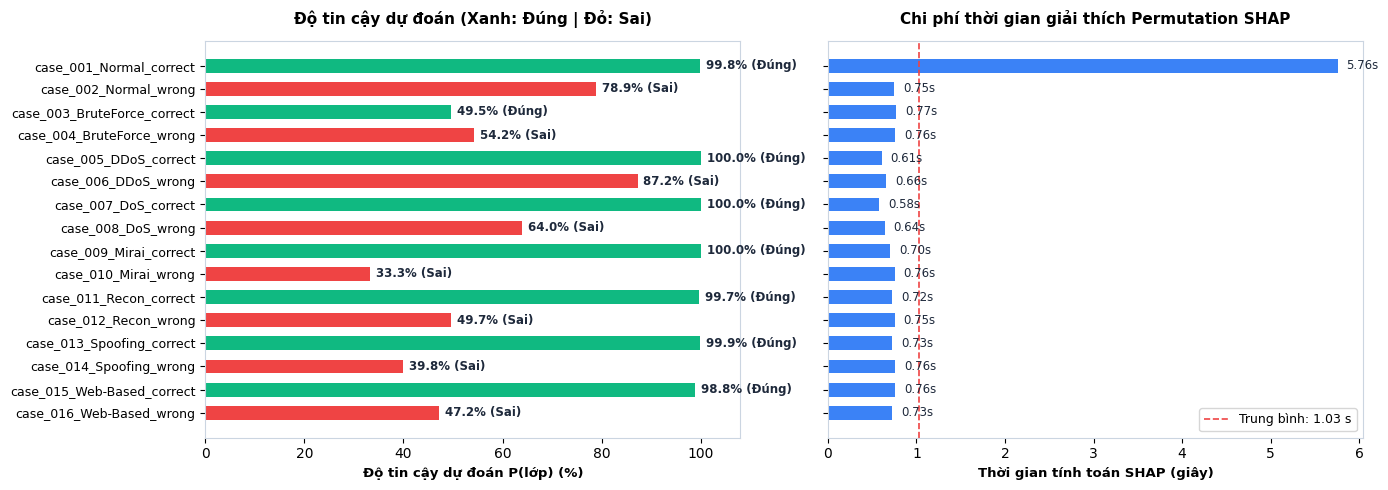

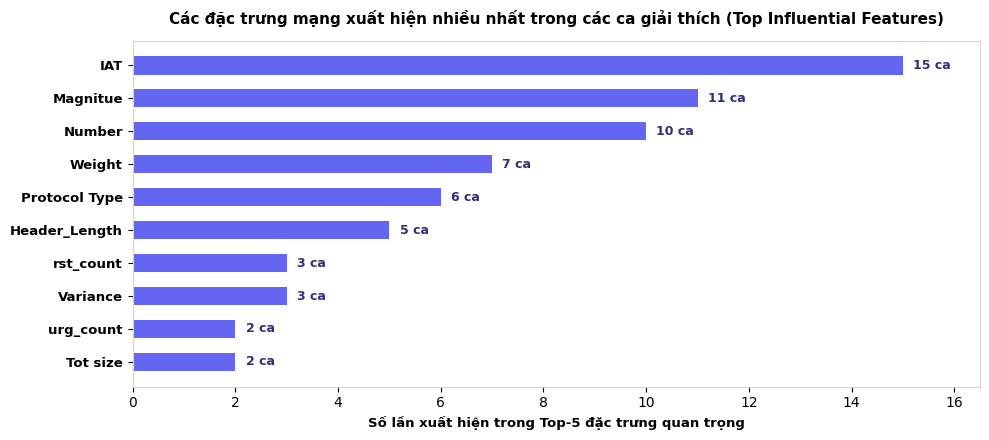


[OK] QUÁ TRÌNH GIẢI THÍCH CỤC BỘ SHAP ĐÃ HOÀN TẤT THÀNH CÔNG!
📁 Kết quả, báo cáo và biểu đồ đã lưu tại: /kaggle/working/xai_shap_runs/shap_20261022_021654_2555e479


In [13]:
summary = pd.DataFrame(case_results)
print("\n" + "═" * 78)
print(" 🎓 BÁO CÁO TỔNG HỢP KẾT QUẢ GIẢI THÍCH SHAP (EXECUTIVE REPORT)")
print("═" * 78)

# 1. Bảng tóm tắt chỉ số tổng quan
summary_cards = pd.DataFrame([
    {"Chỉ số đánh giá": "Mô hình mục tiêu", "Giá trị": MODEL_ID, "Chi tiết": "Stacking DT+RF+HGB -> XGBoost Meta"},
    {"Chỉ số đánh giá": "Tổng số ca giải thích cục bộ", "Giá trị": f"{len(summary)} ca", "Chi tiết": f"{summary['correct'].sum()} ca Đúng | {(~summary['correct']).sum()} ca Nhầm lẫn"},
    {"Chỉ số đánh giá": "Thời gian tính toán trung bình", "Giá trị": f"{summary['shap_seconds'].mean():.2f} giây / ca", "Chi tiết": f"Tổng thời gian: {summary['shap_seconds'].sum():.2f} s"},
    {"Chỉ số đánh giá": "Sai số bảo toàn lớn nhất", "Giá trị": f"{summary['max_additivity_error_all_classes'].max():.2e}", "Chi tiết": f"Ngưỡng cho phép: {ADDITIVITY_TOLERANCE:.0e}"},
    {"Chỉ số đánh giá": "Thời gian suy luận toàn Validation", "Giá trị": f"{validation_predict_seconds:.2f} s", "Chi tiết": f"{validation_predict_seconds / len(X_val) * 1e6:.1f} µs / mẫu"},
    {"Chỉ số đánh giá": "Môi trường thực nghiệm", "Giá trị": f"CPU ({N_JOBS} threads)", "Chi tiết": f"{hardware['ram_gib']:.2f} GiB RAM | {cpu_name}"},
])
display(summary_cards)

# 2. Bảng tổng hợp các ca phân tích (Styled Table)
print("\n[1] BẢNG CHI TIẾT CÁC CA ĐÃ GIẢI THÍCH (EXPLAINED VALIDATION CASES):")
styled_summary = summary[[
    "case_id", "true_class", "predicted_class", "correct",
    "predicted_probability", "base_probability", "shap_seconds"
]].copy()
styled_summary["Kết quả"] = styled_summary["correct"].map({True: "✅ Đúng", False: "⚠️ Sai"})
styled_summary_view = styled_summary.drop(columns=["correct"]).style.format({
    "predicted_probability": "{:.2%}",
    "base_probability": "{:.4f}",
    "shap_seconds": "{:.2f} s"
}).background_gradient(subset=["predicted_probability"], cmap="Blues", vmin=0.5, vmax=1.0)
display(styled_summary_view)

# 3. Bảng Top đặc trưng
print("\n[2] TOP ĐẶC TRƯNG TÁC ĐỘNG MẠNH NHẤT THEO TỪNG DỰ ĐOÁN:")
top_df = pd.DataFrame(top_feature_records)[[
    "case_id", "explained_class", "rank", "feature", "value", "shap_value", "direction",
]].copy()
display(top_df.head(15).round(4))

# 4. Trực quan hóa tổng hợp cho Báo cáo đồ án tốt nghiệp
# Đồ thị A: Độ tin cậy dự đoán và thời gian thực thi theo từng ca
fig_overview, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
bar_colors = ["#10b981" if c else "#ef4444" for c in summary["correct"]]
y_pos = np.arange(len(summary))

ax1.barh(y_pos, summary["predicted_probability"] * 100, color=bar_colors, height=0.6, edgecolor="none")
ax1.set_yticks(y_pos)
ax1.set_yticklabels(summary["case_id"], fontsize=9)
ax1.invert_yaxis()
ax1.set_xlim(0, 108)
ax1.set_xlabel("Độ tin cậy dự đoán P(lớp) (%)", fontsize=9.5, fontweight="bold")
ax1.set_title("Độ tin cậy dự đoán (Xanh: Đúng | Đỏ: Sai)", fontsize=11, fontweight="bold", pad=12)
for i, (p, c) in enumerate(zip(summary["predicted_probability"], summary["correct"])):
    status_tag = "Đúng" if c else "Sai"
    ax1.text(p * 100 + 1.2, i, f"{p * 100:.1f}% ({status_tag})", va="center", fontsize=8.5, fontweight="bold", color="#1e293b")

ax2.barh(y_pos, summary["shap_seconds"], color="#3b82f6", height=0.6, edgecolor="none")
mean_lat = summary["shap_seconds"].mean()
ax2.axvline(mean_lat, color="#ef4444", linestyle="--", linewidth=1.2, label=f"Trung bình: {mean_lat:.2f} s")
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.invert_yaxis()
ax2.set_xlabel("Thời gian tính toán SHAP (giây)", fontsize=9.5, fontweight="bold")
ax2.set_title("Chi phí thời gian giải thích Permutation SHAP", fontsize=11, fontweight="bold", pad=12)
ax2.legend(loc="lower right", fontsize=9)
for i, s in enumerate(summary["shap_seconds"]):
    ax2.text(s + 0.1, i, f"{s:.2f}s", va="center", fontsize=8.5, color="#1e293b")

plt.tight_layout()
fig_overview.savefig(OUTPUT_DIR / "shap_cohort_performance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig_overview)

# Đồ thị B: Tần suất xuất hiện của các đặc trưng quan trọng nhất (Global Impact from Local SHAP)
feature_counts = top_df["feature"].value_counts().head(10)
fig_feat, ax_f = plt.subplots(figsize=(10, 4.5))
y_f = np.arange(len(feature_counts))
ax_f.barh(y_f, feature_counts.values, color="#6366f1", height=0.55, edgecolor="none")
ax_f.set_yticks(y_f)
ax_f.set_yticklabels(feature_counts.index, fontsize=9.5, fontweight="bold")
ax_f.invert_yaxis()
ax_f.set_xlabel("Số lần xuất hiện trong Top-5 đặc trưng quan trọng", fontsize=9.5, fontweight="bold")
ax_f.set_title("Các đặc trưng mạng xuất hiện nhiều nhất trong các ca giải thích (Top Influential Features)", fontsize=11, fontweight="bold", pad=12)
for i, v in enumerate(feature_counts.values):
    ax_f.text(v + 0.2, i, f"{v} ca", va="center", fontsize=9, fontweight="bold", color="#312e81")
ax_f.set_xlim(0, max(feature_counts.values) + 1.5)
plt.tight_layout()
fig_feat.savefig(OUTPUT_DIR / "shap_global_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig_feat)

# 5. Lưu trữ checksum và trạng thái kết thúc
output_checksums = {}
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file() and path.name not in ["output_checksums.json", "run_status.json"] and "__pycache__" not in path.parts:
        output_checksums[str(path.relative_to(OUTPUT_DIR))] = sha256_file(path)
write_json(OUTPUT_DIR / "output_checksums.json", output_checksums)
write_json(OUTPUT_DIR / "run_status.json", {
    "status": "complete", "run_id": RUN_ID, "protocol": PROTOCOL,
    "source_xgb_run_id": SOURCE_RUN_ID, "data_run_id": DATA_RUN_ID, "model_id": MODEL_ID,
    "explained_cases": len(summary), "test_loaded": False, "model_refitted": False,
    "finished_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "total_seconds": time.perf_counter() - SESSION_START,
})

print(f"\n[OK] QUÁ TRÌNH GIẢI THÍCH CỤC BỘ SHAP ĐÃ HOÀN TẤT THÀNH CÔNG!")
print(f"📁 Kết quả, báo cáo và biểu đồ đã lưu tại: {OUTPUT_DIR}")
